# Data Structures & Algorithms: Advanced Tries, String Matching, Range Queries and Number Theory

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and the earlier notebooks of this module (`01`–`10` in this folder), or a university student revising for a DSA exam or coding interview.
>
> **What you will learn:**
> - **Tries** (prefix trees): insert, search, prefix search, delete, ranked autocomplete, prefix counting; the **compressed trie / radix tree**; the **binary trie** for the maximum XOR of a pair.
> - **String matching**: naive search, **Rabin-Karp** (rolling hash, spurious hits), **KMP** (the LPS array), the **Z-algorithm**, and the **longest palindromic substring** (expand-around-centre and **Manacher's algorithm**), with a benchmark.
> - **Range queries**: the **segment tree** (build, query, point update, **lazy propagation**), the **Fenwick tree** (binary indexed tree), and the **sparse table** for range-minimum queries.
> - **Number theory**: GCD/LCM, **extended Euclid**, the **Sieve of Eratosthenes**, prime factorisation, **fast modular exponentiation**, the **modular inverse**, **Euler's totient**, **nCr mod p**, and the basics of **RSA**.
> - A recap of **disjoint-set union** (union-find).
> - How to **verify** every algorithm against a slow but obviously-correct brute force.
>
> **Prerequisites:** Python functions, lists, dicts and classes ([`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), [`01_Python/03_advanced.ipynb`](../../01_Python/03_advanced.ipynb)); Big-O notation and recursion ([`01_complexity_analysis_and_recursion.ipynb`](01_complexity_analysis_and_recursion.ipynb)), hashing ([`04_hashing.ipynb`](04_hashing.ipynb)), trees and heaps ([`06_trees_bst_and_heaps.ipynb`](06_trees_bst_and_heaps.ipynb)); modular arithmetic is explained from zero here.
>
> **Time needed:** about 3–4 hours to read and run; longer if you do the practice problems.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook executes in well under a minute.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*; it is recommended for BS/MS AI students and for interview preparation, but the rest of the course does not depend on it.

## Explained simply

Computers are asked the same kinds of questions over and over: *"which saved words start with these letters?"*, *"where does this word appear in a long text?"*, *"what is the total of everything between day 40 and day 90?"*, *"what is the remainder when a giant number is divided by another?"*. Answering them the obvious way means re-reading everything every time, which becomes painfully slow when there are millions of items. This notebook shows clever ways to **organise the data once** so that every later question takes only a few steps. A **trie** works like the thumb tabs of a dictionary: you jump to the "c" section, then "ca", and never look at words starting with "d". A **range-query tree** works like a shop manager who already knows each week's and each month's sales, so a yearly total needs a handful of additions instead of 365. Number tricks such as remainders ("clock arithmetic", where 9 o'clock plus 5 hours is 2 o'clock) are what keep passwords, hashing and online banking working.

**Tiny example.** Daily sales for 4 days are `3, 5, 2, 6`. Write down the running totals once: `0, 3, 8, 10, 16`. Now "sales from day 2 to day 4" is just `16 − 3 = 13` (check: 5 + 2 + 6 = 13): one subtraction instead of adding up every day. Segment trees and Fenwick trees (section 3) keep this trick working even when sales figures change.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Trie | a tree of letters where words with the same start share a path | phone keyboard suggestions, search-box autocomplete, LLM tokenizers |
| String matching (KMP, Z, Rabin-Karp) | find a word in a long text without re-reading letters you already checked | Ctrl+F, spam and plagiarism filters, stop-words in chatbots |
| Range queries + number theory | pre-computed totals for fast "sum/min between a and b", and arithmetic with remainders | sales dashboards, sampling in reinforcement learning, encryption (RSA) and hashing |

## Contents

| # | Part | Key idea |
|---|---|---|
| 0 | Setup | imports, timing helper, a counter of passed brute-force checks |
| 1 | Tries | share common prefixes; cost depends on the word length, not on how many words are stored |
| 2 | String matching | never re-examine text characters you already know about |
| 3 | Range queries | pre-compute sums/minimums over blocks so a query touches only $O(\log n)$ blocks |
| 4 | Number theory | Euclid, sieves, and doing arithmetic "on a clock" (modulo $m$) |
| 5 | Disjoint-set union | merge groups and ask "same group?" in almost $O(1)$ |
| 6 | Verify everything | one table of all brute-force checks |
| 7 | Cheat sheet, modern AI, recap, practice | |

---
## 0. Setup

We only need the Python standard library, NumPy, pandas, matplotlib and networkx. `best_time` runs a function a few times and keeps the fastest run (the fastest run is the least disturbed by other programs on your computer). `CHECKS` counts how many random brute-force comparisons each algorithm has passed, so at the end we can show one summary table.

In [1]:
import math                                   # gcd, comb, isqrt, log
import random                                 # random test inputs
import string                                 # string.ascii_lowercase
import sys
import time                                   # time.perf_counter for benchmarks
import heapq                                  # heap for ranked autocomplete
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

random.seed(42)                               # same "random" tests every run
np.random.seed(42)
pd.set_option("display.width", 140)
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "green": "#1baf7a", "grey": "#8a8984", "red": "#e34948", "yellow": "#ffd27f"}


def best_time(fn, *args, repeat=3):
    # Run fn(*args) `repeat` times; return (fastest time in seconds, result of the last run)
    best, result = float("inf"), None
    for _ in range(repeat):
        t0 = time.perf_counter()
        result = fn(*args)
        best = min(best, time.perf_counter() - t0)
    return best, result


CHECKS = Counter()                            # algorithm name -> number of brute-force comparisons passed
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__)

Python 3.12.3 | NumPy 2.4.6 | pandas 2.3.3 | networkx 3.7


A small helper to **draw a rooted tree** with networkx and matplotlib (we do not use graphviz). Leaves are placed left to right, and each parent sits above the middle of its children.

In [2]:
def draw_tree(edges, root, node_labels, ax, title, edge_labels=None, highlight=(), node_size=900, font_size=9):
    # edges: list of (parent, child) pairs; node_labels: dict node -> text shown inside the circle
    G = nx.DiGraph()
    G.add_node(root)
    G.add_edges_from(edges)
    pos, next_x = {}, [0]

    def place(u, depth):                      # post-order: place children first, then the parent above them
        kids = list(G.successors(u))
        if not kids:
            pos[u] = (next_x[0], -depth)
            next_x[0] += 1
        else:
            for k in kids:
                place(k, depth + 1)
            pos[u] = (sum(pos[k][0] for k in kids) / len(kids), -depth)

    place(root, 0)
    colors = [COLORS["yellow"] if n in highlight else "#cfe3ff" for n in G.nodes]
    nx.draw(G, pos, ax=ax, labels=node_labels, node_color=colors, node_size=node_size,
            font_size=font_size, arrows=False, edgecolors="#333333")
    if edge_labels:
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax, font_size=font_size + 1,
                                     font_color=COLORS["red"], rotate=False)
    ax.set_title(title)
    ax.axis("off")

---
## 1. Tries (prefix trees)

> **In plain English:** store words letter by letter so that words with the same beginning share the same path, and lookups only depend on the word's length.

### 1.1 Intuition

Think of a paper dictionary with thumb tabs: to find *"cart"* you first open the **c** section, then the **ca** pages, then **car**... You never look at words starting with **d**. A **trie** (from re*trie*val, usually pronounced "try") does exactly that.

**Trie** — a rooted tree in which every edge is labelled with one character, and the path from the root to a node spells a **prefix**. A node is marked as a **word end** if the prefix it spells is a stored word. Words that share a prefix share the same path.

Hand example with the words `car, cart, cat, dog, do`:

```
            (root)
           /      \
          c        d
          |        |
          a        o*        * = a word ends here ("do")
         / \       |
        r*  t*     g*        "car", "cat", "dog"
        |
        t*                   "cart"
```

| operation | what we do | cost |
|---|---|---|
| `insert(w)` | walk down, creating missing children | $O(L)$, $L = $ length of `w` |
| `search(w)` | walk down; answer = "does the node exist **and** is it a word end?" | $O(L)$ |
| `starts_with(p)` | walk down; answer = "does the node exist?" | $O(L)$ |
| `count_prefix(p)` | walk down, read a counter stored in the node | $O(L)$ |
| `delete(w)` | walk down decrementing counters, cut branches that no word uses any more | $O(L)$ |
| `autocomplete(p, k)` | walk to `p`, collect the words below it, keep the `k` most popular with a heap | $O(L + S\log k)$, $S$ = size of the subtree |

The key point: the cost depends on the **length of the word**, not on the number $N$ of stored words. A sorted list needs $O(L\log N)$ for a lookup (binary search, each comparison costs up to $L$); a hash set needs $O(L)$ on average but **cannot** answer prefix questions.

**Space:** at most one node per character inserted, i.e. $O(\text{total characters})$; each node stores a dict of children.

In [3]:
class TrieNode:
    __slots__ = ("children", "is_end", "prefix_count", "freq")   # __slots__ saves memory per node

    def __init__(self):
        self.children = {}        # character -> child TrieNode
        self.is_end = False       # True if a stored word ends exactly at this node
        self.prefix_count = 0     # how many stored words pass through (or end at) this node
        self.freq = 0             # popularity of the word ending here (used to rank autocomplete)


class Trie:
    def __init__(self):
        self.root = TrieNode()
        self.size = 0             # number of distinct stored words

    def _walk(self, s):
        # Follow the characters of s from the root; return the node reached, or None if the path breaks
        node = self.root
        for ch in s:
            node = node.children.get(ch)
            if node is None:
                return None
        return node

    def insert(self, word, freq=1):
        existing = self._walk(word)
        if existing is not None and existing.is_end:   # already stored: only increase its popularity
            existing.freq += freq
            return
        node = self.root
        node.prefix_count += 1                          # the root is a prefix ("") of every word
        for ch in word:
            node = node.children.setdefault(ch, TrieNode())   # create the child if it is missing
            node.prefix_count += 1
        node.is_end = True
        node.freq = freq
        self.size += 1

    def search(self, word):
        node = self._walk(word)
        return node is not None and node.is_end         # the path must exist AND end at a word

    def starts_with(self, prefix):
        node = self._walk(prefix)
        return node is not None and node.prefix_count > 0   # > 0 also handles the empty prefix of an empty trie

    def count_prefix(self, prefix):
        node = self._walk(prefix)
        return 0 if node is None else node.prefix_count

    def delete(self, word):
        if not self.search(word):
            return False
        node = self.root
        node.prefix_count -= 1
        for ch in word:
            child = node.children[ch]
            child.prefix_count -= 1
            if child.prefix_count == 0:                 # no other word uses this branch: cut the whole branch
                del node.children[ch]
                self.size -= 1
                return True
            node = child
        node.is_end = False                             # the word was a prefix of another word: just unmark it
        node.freq = 0
        self.size -= 1
        return True

    def words_with_prefix(self, prefix):
        # Depth-first search below the prefix node; returns [(word, freq), ...]
        start = self._walk(prefix)
        if start is None:
            return []
        out, stack = [], [(start, prefix)]
        while stack:
            node, spelled = stack.pop()
            if node.is_end:
                out.append((spelled, node.freq))
            for ch, child in node.children.items():
                stack.append((child, spelled + ch))
        return out

    def autocomplete(self, prefix, k=3):
        # k most frequent completions; ties broken alphabetically. heapq.nsmallest keeps only k items: O(S log k)
        best = heapq.nsmallest(k, self.words_with_prefix(prefix), key=lambda wf: (-wf[1], wf[0]))
        return [w for w, _ in best]

    def count_nodes(self):
        stack, total = [self.root], 0
        while stack:
            node = stack.pop()
            total += 1
            stack.extend(node.children.values())
        return total

Let us build the trie from the hand example (with made-up popularity counts, like a search log) and ask it questions.

In [4]:
query_log = {"car": 50, "cart": 20, "cat": 35, "dog": 40, "do": 10, "card": 25, "care": 5}
trie = Trie()
for w, f in query_log.items():
    trie.insert(w, f)

print("distinct words    :", trie.size, "| nodes (incl. root):", trie.count_nodes())
print("search('car')     :", trie.search("car"))
print("search('ca')      :", trie.search("ca"), " <- 'ca' is only a prefix, not a stored word")
print("starts_with('ca') :", trie.starts_with("ca"))
print("count_prefix('ca'):", trie.count_prefix("ca"), " (car, cart, cat, card, care)")
print("count_prefix('car'):", trie.count_prefix("car"), " (car, cart, card, care)")
print("autocomplete('ca', 3):", trie.autocomplete("ca", 3))
print("autocomplete('d', 3) :", trie.autocomplete("d", 3))

trie.delete("cart")
print("\nafter delete('cart'): search('cart') =", trie.search("cart"), "| search('car') =", trie.search("car"),
      "| count_prefix('car') =", trie.count_prefix("car"))
trie.delete("do")
print("after delete('do')  : search('do') =", trie.search("do"), "| search('dog') =", trie.search("dog"))

distinct words    : 7 | nodes (incl. root): 11
search('car')     : True
search('ca')      : False  <- 'ca' is only a prefix, not a stored word
starts_with('ca') : True
count_prefix('ca'): 5  (car, cart, cat, card, care)
count_prefix('car'): 4  (car, cart, card, care)
autocomplete('ca', 3): ['car', 'cat', 'card']
autocomplete('d', 3) : ['dog', 'do']

after delete('cart'): search('cart') = False | search('car') = True | count_prefix('car') = 3
after delete('do')  : search('do') = False | search('dog') = True


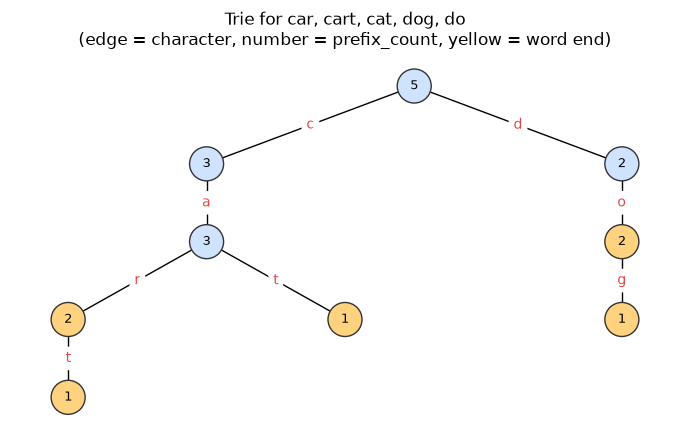

In [5]:
# Draw the trie (rebuilt with the hand-example words); yellow = a word ends at that node
small = Trie()
for w in ["car", "cart", "cat", "dog", "do"]:
    small.insert(w)

edges, labels, elabels, ends, counter = [], {}, {}, set(), [0]
def collect(node, node_id):
    labels[node_id] = str(node.prefix_count)          # show prefix_count inside each node
    if node.is_end:
        ends.add(node_id)
    for ch, child in sorted(node.children.items()):
        counter[0] += 1
        cid = counter[0]
        edges.append((node_id, cid))
        elabels[(node_id, cid)] = ch
        collect(child, cid)
collect(small.root, 0)

fig, ax = plt.subplots(figsize=(7, 4.5))
draw_tree(edges, 0, labels, ax, "Trie for car, cart, cat, dog, do\n(edge = character, number = prefix_count, yellow = word end)",
          edge_labels=elabels, highlight=ends, node_size=600)
plt.tight_layout(); plt.show()

**What just happened?** Every word is a path from the root. The number in each node is `prefix_count`, so `count_prefix("ca")` is a single walk of two steps followed by reading one number. Autocomplete walks to the prefix node and then only searches **that** subtree, ranking candidates with a heap. Deleting `"cart"` removed one node (no other word used it); deleting `"do"` only removed the word-end mark, because `"dog"` still needs the node.

### 1.2 Verify the trie against a brute force

The brute force is a plain Python `dict` of words: prefix questions are answered by scanning **every** word with `str.startswith`. It is slow ($O(N\cdot L)$ per query) but obviously correct. We run thousands of random operations on both and demand identical answers.

In [6]:
def brute_autocomplete(d, prefix, k):
    return [w for _, w in sorted((-f, w) for w, f in d.items() if w.startswith(prefix))[:k]]

def random_word(alphabet="abc", max_len=6):
    return "".join(random.choice(alphabet) for _ in range(random.randint(0, max_len)))   # length 0 allowed

for trial in range(30):
    t, ref = Trie(), {}                                   # trie vs dict reference
    for step in range(300):
        op, w = random.random(), random_word()
        if op < 0.45:
            f = random.randint(1, 9)
            t.insert(w, f); ref[w] = ref.get(w, 0) + f
        elif op < 0.65:
            assert t.delete(w) == (w in ref)
            ref.pop(w, None)
        else:
            assert t.search(w) == (w in ref)
            assert t.starts_with(w) == any(x.startswith(w) for x in ref)
            assert t.count_prefix(w) == sum(x.startswith(w) for x in ref)
            assert t.autocomplete(w, 3) == brute_autocomplete(ref, w, 3)
        assert t.size == len(ref)
        CHECKS["trie"] += 1
print("trie matches the brute-force dict on", CHECKS["trie"], "random operations")

trie matches the brute-force dict on 9000 random operations


> ⚠️ **Common mistake:** `search("ca")` returning `True` because the node for `"ca"` exists. A node existing only means *some* word starts with `"ca"`; you must also check `is_end`.

> ⚠️ **Common mistake:** deleting a word by removing its last node only. If that node has children (deleting `"car"` while `"cart"` is stored) you would destroy other words; if you never prune, `starts_with` gives wrong answers for deleted branches. Counters make both cases easy.

### 1.3 Compressed trie / radix tree (briefly)

In a plain trie, long chains of single-child nodes waste memory (each node is a Python object with a dict). A **radix tree** (also called a **compressed trie** or **Patricia trie**) merges every chain of single-child nodes into **one edge labelled with a whole string**. Inserting a word that diverges in the middle of an edge **splits** that edge.

```
plain trie of "romane", "romanus", "romulus":      radix tree:
r-o-m-a-n-e*                                         (root)
        \-u-s*                                         |  "rom"
    \-u-l-u-s*                                        (o)
                                                    /     \
                                               "an"        "ulus"*
                                              /    \
                                           "e"*    "us"*
```

In [7]:
class RadixNode:
    def __init__(self):
        self.edges = {}           # first character of the edge label -> (label string, child RadixNode)
        self.is_end = False


class RadixTree:
    def __init__(self):
        self.root = RadixNode()

    def insert(self, word):
        node = self.root
        while True:
            if not word:                                  # consumed the whole word: mark the end here
                node.is_end = True
                return
            edge = node.edges.get(word[0])
            if edge is None:                              # no edge starts with this character: add one leaf edge
                leaf = RadixNode(); leaf.is_end = True
                node.edges[word[0]] = (word, leaf)
                return
            label, child = edge
            i = 0                                         # length of the common prefix of label and word
            while i < len(label) and i < len(word) and label[i] == word[i]:
                i += 1
            if i == len(label):                           # the whole edge matches: continue below it
                node, word = child, word[i:]
                continue
            mid = RadixNode()                             # the word leaves the edge in the middle: split the edge
            mid.edges[label[i]] = (label[i:], child)      # lower half keeps the old child
            node.edges[word[0]] = (label[:i], mid)        # upper half points to the new middle node
            node, word = mid, word[i:]                    # the loop then adds the rest of the word under mid

    def search(self, word):
        node = self.root
        while word:
            edge = node.edges.get(word[0])
            if edge is None or not word.startswith(edge[0]):
                return False
            node, word = edge[1], word[len(edge[0]):]
        return node.is_end

    def count_nodes(self):
        stack, total = [self.root], 0
        while stack:
            n = stack.pop(); total += 1
            stack.extend(child for _, child in n.edges.values())
        return total

    def show(self, node=None, indent=""):
        node = node or self.root
        for _, (label, child) in sorted(node.edges.items()):
            print(f"{indent}--{label}{'*' if child.is_end else ''}")
            self.show(child, indent + "    ")


latin = ["romane", "romanus", "romulus", "rubens", "ruber", "rubicon", "rubicundus"]
rt, plain = RadixTree(), Trie()
for w in latin:
    rt.insert(w); plain.insert(w)
rt.show()
print(f"\nnodes: plain trie = {plain.count_nodes()}, radix tree = {rt.count_nodes()}")

--r
    --om
        --an
            --e*
            --us*
        --ulus*
    --ub
        --e
            --ns*
            --r*
        --ic
            --on*
            --undus*

nodes: plain trie = 28, radix tree = 14


In [8]:
# Verify: radix-tree search must equal set membership for random word sets (including prefixes of each other)
for trial in range(200):
    words = {random_word("ab", 7) for _ in range(random.randint(1, 30))}
    r = RadixTree()
    for w in words:
        r.insert(w)
    for _ in range(50):
        q = random_word("ab", 8)
        assert r.search(q) == (q in words)
        CHECKS["radix tree"] += 1
print("radix tree matches a Python set on", CHECKS["radix tree"], "random lookups")

radix tree matches a Python set on 10000 random lookups


**What just happened?** The radix tree stores the same 7 words with half as many nodes (14 instead of 28) because chains such as `i-c-u-n-d-u-s` became a single edge. Search cost is still $O(L)$ character comparisons. Radix trees are used for IP routing tables (longest-prefix match), in-memory database indexes, and key-value stores (Redis uses a radix tree, "rax", for its Streams).

### 1.4 The binary (bitwise) trie: maximum XOR of a pair

**XOR** (`^` in Python) compares two numbers bit by bit: the result bit is `1` when the bits differ. To make `a ^ b` as large as possible we want the **highest** bits to differ.

**Binary trie** — a trie whose alphabet is `{0, 1}`: each number is inserted as its bits from the most significant to the least significant (here 31 bits, enough for non-negative 32-bit integers).

To find the best partner for `x`, walk down the trie and at every level **prefer the opposite bit** of `x` (that bit of the XOR becomes 1). This greedy choice is optimal because a 1 in bit $b$ is worth more than all lower bits together ($2^b > 2^{b-1} + \dots + 1$).

Hand example with `[3, 10, 5, 25, 2, 8]` (5-bit binary shown):

| number | bits | best partner | XOR |
|---|---|---|---|
| 5  | `00101` | 25 = `11001` | `11100` = **28** |
| 25 | `11001` | 5 = `00101`  | 28 |
| 10 | `01010` | 25 = `11001` | `10011` = 19 |

So the answer is **28**. Brute force tries all $\binom{n}{2}$ pairs: $O(n^2)$. The binary trie needs $O(n\cdot B)$ with $B = 31$ bits.

In [9]:
BITS = 31                                       # numbers in [0, 2**31)

class BinaryTrie:
    def __init__(self):
        self.root = [None, None]                # a node is just [child_for_bit_0, child_for_bit_1]

    def insert(self, x):
        node = self.root
        for b in range(BITS - 1, -1, -1):       # most significant bit first
            bit = (x >> b) & 1
            if node[bit] is None:
                node[bit] = [None, None]
            node = node[bit]

    def max_xor_with(self, x):
        node, best = self.root, 0
        for b in range(BITS - 1, -1, -1):
            bit = (x >> b) & 1
            want = 1 - bit                      # the opposite bit makes this XOR bit equal to 1
            if node[want] is not None:
                best |= 1 << b
                node = node[want]
            else:
                node = node[bit]                # forced: only the same bit exists
        return best


def max_xor_pair(nums):
    trie = BinaryTrie()
    trie.insert(nums[0])
    best = 0
    for x in nums[1:]:                          # pair each number with the best EARLIER number
        best = max(best, trie.max_xor_with(x))
        trie.insert(x)
    return best


def max_xor_brute(nums):
    return max(a ^ b for i, a in enumerate(nums) for b in nums[i + 1:])


print("max XOR of [3, 10, 5, 25, 2, 8] =", max_xor_pair([3, 10, 5, 25, 2, 8]))
for trial in range(300):
    nums = [random.randrange(2**BITS) for _ in range(random.randint(2, 40))]
    assert max_xor_pair(nums) == max_xor_brute(nums)
    CHECKS["binary trie max XOR"] += 1

nums = [random.randrange(2**BITS) for _ in range(3000)]
t_brute, r1 = best_time(max_xor_brute, nums, repeat=1)
t_trie, r2 = best_time(max_xor_pair, nums, repeat=1)
assert r1 == r2
print(f"n = 3000: brute force {t_brute:.3f} s, binary trie {t_trie:.3f} s, same answer {r1}")

max XOR of [3, 10, 5, 25, 2, 8] = 28


n = 3000: brute force 2.059 s, binary trie 0.342 s, same answer 2147483273


**What just happened?** The binary trie gave the same answer as the brute force on 300 random arrays, and on 3,000 numbers it is much faster: the brute force performs about 4.5 million XORs while the trie performs $3000 \times 31 \times 2$ steps. The gap grows quadratically with $n$.

> 🎓 **Exam / interview tip:** "Maximum XOR of two numbers", "maximum XOR subarray" (insert **prefix XORs** into the binary trie) and "count pairs with XOR less than k" are classic binary-trie questions. Say the complexity as $O(n \cdot B)$ where $B$ is the number of bits.

---
## 2. String matching

> **In plain English:** find every place a short pattern appears in a long text, without re-checking letters we have already compared.

**Pattern matching problem** — given a **text** $T$ of length $n$ and a **pattern** $P$ of length $m$, find every position $i$ such that $T[i \dots i+m-1] = P$.

Everyday analogy: pressing Ctrl+F in a document. All algorithms below return the same list of positions; they differ in how much work they repeat.

### 2.1 Naive search

Slide the pattern one position at a time and compare character by character.

```
T: A A A A A B        P: A A B
   A A x               position 0: 2 matches then mismatch
     A A x             position 1: 2 matches then mismatch
       A A x           position 2: ...
         A A B         position 3: match!
```

Worst case: about $(n-m+1)\cdot m$ comparisons, i.e. $O(nm)$ (text `aaaa...a`, pattern `aa...ab`). On random text it usually stops after one or two characters, so it is often fine in practice.

In [10]:
def naive_search(text, pat):
    n, m = len(text), len(pat)
    out = []
    for i in range(n - m + 1):                 # every possible starting position
        j = 0
        while j < m and text[i + j] == pat[j]:  # compare character by character
            j += 1
        if j == m:
            out.append(i)
    return out

def slice_reference(text, pat):
    # The obviously-correct brute force we compare everything against
    return [i for i in range(len(text) - len(pat) + 1) if text[i:i + len(pat)] == pat]

print(naive_search("AAAAAB", "AAB"), naive_search("abracadabra", "abra"))

[3] [0, 7]


### 2.2 Rabin-Karp: compare hashes, not strings

Idea: turn each length-$m$ window into a number (a **hash**) and compare numbers. Treat the string as a number in base $d$ and reduce it modulo a prime $q$:

$$h(s_0 s_1 \dots s_{m-1}) = (s_0 d^{m-1} + s_1 d^{m-2} + \dots + s_{m-1}) \bmod q$$

**Rolling hash** — the next window's hash is computed from the previous one in $O(1)$: remove the leading character, shift, add the new character:

$$h_{i+1} = \big((h_i - s_i \cdot d^{m-1})\cdot d + s_{i+m}\big) \bmod q$$

Different strings can have the same hash. When the hashes are equal but the strings are not, that is a **spurious hit**; Rabin-Karp therefore **verifies** every hash match by comparing the actual characters.

| case | time |
|---|---|
| expected (good prime, few spurious hits) | $O(n + m)$ |
| worst (every window collides, e.g. tiny $q$) | $O(nm)$ |

Worked example from CLRS (Cormen et al., chapter 32): digits, $d = 10$, $q = 13$, $T$ = `2359023141526739921`, $P$ = `31415`. Since $31415 \bmod 13 = 7$, every window whose value is $\equiv 7 \pmod{13}$ is a candidate.

In [11]:
def rabin_karp(text, pat, base=256, mod=1_000_000_007, value=ord, stats=None):
    n, m = len(text), len(pat)
    if m > n:
        return []
    high = pow(base, m - 1, mod)                 # weight of the leading character, d^(m-1) mod q
    hp = ht = 0
    for i in range(m):                           # hash of the pattern and of the first window
        hp = (hp * base + value(pat[i])) % mod
        ht = (ht * base + value(text[i])) % mod
    out, spurious, trace = [], 0, []
    for i in range(n - m + 1):
        if ht == hp:                             # candidate: verify character by character
            if text[i:i + m] == pat:
                out.append(i); kind = "match"
            else:
                spurious += 1; kind = "SPURIOUS"
        else:
            kind = ""
        if stats is not None and stats.get("trace"):
            trace.append((i, text[i:i + m], ht, kind))
        if i < n - m:                            # roll: drop text[i], add text[i+m]
            ht = ((ht - value(text[i]) * high) * base + value(text[i + m])) % mod
    if stats is not None:
        stats["spurious"], stats["rows"] = spurious, trace
    return out

st = {"trace": True}
pos = rabin_karp("2359023141526739921", "31415", base=10, mod=13, value=int, stats=st)
trace_df = pd.DataFrame(st["rows"], columns=["i", "window", "hash mod 13", "result"])
print("pattern hash:", 31415 % 13, "| matches at", pos, "| spurious hits:", st["spurious"])
trace_df[trace_df["hash mod 13"] == 7]

pattern hash: 7 | matches at [6] | spurious hits: 1


,i,window,hash mod 13,result
6,6,31415,7,match
12,12,67399,7,SPURIOUS


In [12]:
# Small modulus -> many spurious hits; large prime -> (almost) none. Same answers either way.
text = "".join(random.choice("abcd") for _ in range(20_000))
pat = text[5000:5008]
for mod in (7, 101, 1_000_000_007):
    s = {}
    res = rabin_karp(text, pat, mod=mod, stats=s)
    assert res == slice_reference(text, pat)
    print(f"mod = {mod:>13,}: matches = {len(res)}, spurious hits = {s['spurious']:,}")

mod =             7: matches = 1, spurious hits = 2,935


mod =           101: matches = 1, spurious hits = 186


mod = 1,000,000,007: matches = 1, spurious hits = 0


**What just happened?** With $q = 7$ about one window in seven collides with the pattern hash and must be checked by hand: the verification step saves correctness, but the speed advantage disappears. With a large prime ($10^9+7$) spurious hits essentially vanish.

> ⚠️ **Common mistake:** skipping the character-by-character verification ("hashes are equal, so the strings are equal"). That is only true with probability, and an attacker can construct collisions for a fixed, known modulus. Production code either verifies, uses two independent hashes, or picks the base at random.

### 2.3 Knuth-Morris-Pratt (KMP)

When the naive method fails after matching `ABAB` of the pattern `ABABC`, it slides by one and re-compares characters it has already seen. KMP observes that the matched part `ABAB` **ends with** `AB`, which is also how the pattern **starts**, so it can continue as if `AB` were already matched, and **the text pointer never moves backwards**.

**LPS array (longest proper prefix which is also a suffix)** — `lps[i]` is the length of the longest proper prefix of `P[0..i]` that is also a suffix of `P[0..i]` ("proper" = not the whole string). This is also called the **failure function** or **prefix function** $\pi$.

Hand computation for `P = ABABCABAB`:

| i | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|---|
| P[i] | A | B | A | B | C | A | B | A | B |
| P[0..i] ends with | – | – | `A` | `AB` | – | `A` | `AB` | `ABA` | `ABAB` |
| lps[i] | 0 | 0 | 1 | 2 | 0 | 1 | 2 | 3 | 4 |

On a mismatch after matching `j` characters, KMP sets `j = lps[j-1]` instead of starting over.

**Complexity:** $O(m)$ to build the LPS array plus $O(n)$ to search, so $O(n+m)$ in the **worst case** (the pointer `j` can go down at most as many times as it went up). Space $O(m)$.

In [13]:
def compute_lps(p):
    lps = [0] * len(p)
    length = 0                          # length of the current longest prefix-suffix
    i = 1
    while i < len(p):
        if p[i] == p[length]:           # extend the current prefix-suffix by one character
            length += 1
            lps[i] = length
            i += 1
        elif length:                    # mismatch: fall back to the next shorter prefix-suffix (do not move i)
            length = lps[length - 1]
        else:                           # nothing to fall back to
            lps[i] = 0
            i += 1
    return lps


def kmp_search(text, pat):
    lps, out, j = compute_lps(pat), [], 0   # j = number of pattern characters currently matched
    for i, ch in enumerate(text):           # i only moves forward
        while j and ch != pat[j]:
            j = lps[j - 1]                  # reuse what we already know about the matched part
        if ch == pat[j]:
            j += 1
        if j == len(pat):                   # full match ending at position i
            out.append(i - j + 1)
            j = lps[j - 1]                  # keep going to find overlapping matches
    return out


def lps_brute(p):
    return [max(k for k in range(i + 1) if p[:k] == p[i + 1 - k:i + 1] and k <= i) for i in range(len(p))]

for p in ["ABABCABAB", "AABAACAABAA", "AAAA", "ABCDE"]:
    print(f"{p:<12} LPS = {compute_lps(p)}")
    assert compute_lps(p) == lps_brute(p)
print("\nKMP finds 'ABAB' in 'ABABABAB' at", kmp_search("ABABABAB", "ABAB"), "(overlapping matches)")

ABABCABAB    LPS = [0, 0, 1, 2, 0, 1, 2, 3, 4]
AABAACAABAA  LPS = [0, 1, 0, 1, 2, 0, 1, 2, 3, 4, 5]
AAAA         LPS = [0, 1, 2, 3]
ABCDE        LPS = [0, 0, 0, 0, 0]

KMP finds 'ABAB' in 'ABABABAB' at [0, 2, 4] (overlapping matches)


### 2.4 The Z-algorithm

**Z-array** — for a string $S$, `Z[i]` is the length of the longest substring starting at `i` that is also a **prefix** of $S$ (we set `Z[0] = len(S)` by convention).

To search, build $S = P + \texttt{\$} + T$ with a separator `$` that appears in neither string. Every position where `Z[i] = m` is a match. The algorithm keeps a window `[l, r)` (the rightmost segment known to equal a prefix) and reuses earlier Z-values inside it, so the total work is $O(n + m)$.

| i | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| S = `aabxaab` | a | a | b | x | a | a | b |
| Z[i] | 7 | 1 | 0 | 0 | 3 | 1 | 0 |

In [14]:
def z_array(s):
    n = len(s)
    z = [0] * n
    if n:
        z[0] = n
    l = r = 0                                      # s[l:r] equals the prefix s[0:r-l]; r is as far right as possible
    for i in range(1, n):
        if i < r:
            z[i] = min(r - i, z[i - l])            # reuse the value from the mirrored position inside the window
        while i + z[i] < n and s[z[i]] == s[i + z[i]]:
            z[i] += 1                              # extend by explicit comparisons (each moves r to the right)
        if i + z[i] > r:
            l, r = i, i + z[i]
    return z


def z_search(text, pat, sep="\x00"):
    assert sep not in text and sep not in pat      # the separator must not occur, or matches could cross it
    s, m = pat + sep + text, len(pat)
    z = z_array(s)
    return [i - m - 1 for i in range(m + 1, len(s)) if z[i] >= m]


def z_brute(s):
    return [len(s)] + [next((k for k in range(len(s) - i, -1, -1) if s[i:i + k] == s[:k])) for i in range(1, len(s))] if s else []

print("Z('aabxaab') =", z_array("aabxaab"))
print("z_search('abracadabra', 'abra') =", z_search("abracadabra", "abra"))
for _ in range(500):
    s = random_word("ab", 12)
    assert z_array(s) == z_brute(s)
    CHECKS["Z-array"] += 1

Z('aabxaab') = [7, 1, 0, 0, 3, 1, 0]
z_search('abracadabra', 'abra') = [0, 7]


### 2.5 Longest palindromic substring: expand-around-centre and Manacher

A **palindrome** reads the same forwards and backwards (`racecar`, `abba`). Every palindrome has a **centre**: a character (odd length) or the gap between two characters (even length). There are $2n-1$ centres.

- **Brute force:** check all $O(n^2)$ substrings, each in $O(n)$: $O(n^3)$.
- **Expand around centre:** for each of the $2n-1$ centres, grow outwards while the two ends match: $O(n^2)$ time, $O(1)$ space. Simple and the usual interview answer.
- **Manacher's algorithm** (1975): insert `#` between characters so every palindrome has odd length, then reuse the **mirror** of the current position inside the rightmost palindrome found so far, exactly like the Z-algorithm reuses its window. $O(n)$ time.

```
s = "abaaba"   ->   t = ^#a#b#a#a#b#a#$    (^ and $ are sentinels so we never run off the ends)
p[i] = radius of the palindrome centred at t[i]; the longest palindrome in s has length max(p)
```

In [15]:
def longest_palindrome_expand(s):
    best_lo, best_len = 0, 0
    for centre in range(2 * len(s) - 1):               # even centres = characters, odd centres = gaps
        lo = centre // 2
        hi = lo + centre % 2
        while lo >= 0 and hi < len(s) and s[lo] == s[hi]:
            lo -= 1; hi += 1                           # grow outwards while both ends match
        length = hi - lo - 1                           # the loop overshot by one on each side
        if length > best_len:                          # strictly longer -> keeps the leftmost of equal length
            best_lo, best_len = lo + 1, length
    return s[best_lo:best_lo + best_len]


def manacher(s):
    t = "^#" + "#".join(s) + "#$"                      # sentinels ^ and $ never match anything
    p = [0] * len(t)                                   # p[i] = palindrome radius around t[i]
    centre = right = 0                                 # the palindrome reaching furthest right so far
    for i in range(1, len(t) - 1):
        if i < right:
            p[i] = min(right - i, p[2 * centre - i])   # mirror position gives a free lower bound
        while t[i + p[i] + 1] == t[i - p[i] - 1]:
            p[i] += 1                                  # try to grow beyond what we know
        if i + p[i] > right:
            centre, right = i, i + p[i]
    length = max(p)
    start = (p.index(length) - length) // 2            # map back from t-coordinates to s-coordinates
    return s[start:start + length]


def longest_palindrome_brute(s):
    best = ""
    for i in range(len(s)):
        for j in range(i, len(s)):
            sub = s[i:j + 1]
            if sub == sub[::-1] and len(sub) > len(best):
                best = sub
    return best


for s in ["babad", "cbbd", "forgeeksskeegfor", "abaaba", "a", ""]:
    print(f"{s!r:20} expand -> {longest_palindrome_expand(s)!r:14} manacher -> {manacher(s)!r}")
for _ in range(1000):
    s = random_word("ab", 14)
    ref = longest_palindrome_brute(s)
    assert longest_palindrome_expand(s) == ref and manacher(s) == ref
    CHECKS["palindrome (expand + Manacher)"] += 1

'babad'              expand -> 'bab'          manacher -> 'bab'
'cbbd'               expand -> 'bb'           manacher -> 'bb'
'forgeeksskeegfor'   expand -> 'geeksskeeg'   manacher -> 'geeksskeeg'
'abaaba'             expand -> 'abaaba'       manacher -> 'abaaba'
'a'                  expand -> 'a'            manacher -> 'a'
''                   expand -> ''             manacher -> ''


**What just happened?** All three methods return the same (leftmost) longest palindrome on 1,000 random strings. For `"babad"` both `"bab"` and `"aba"` are correct answers; our code returns the leftmost.

### 2.6 Verify and benchmark the matchers

First, all five matchers must return **identical** positions on many random inputs, including overlapping patterns and patterns longer than the text. Then we time them on two kinds of input:

1. **Random DNA-like text** (`acgt`), 200,000 characters: naive usually fails after 1–2 characters.
2. **Adversarial text** `aaaa...a` (20,000 characters) with pattern `a...ab` (200 characters): the naive worst case of about $n \cdot m$ comparisons.

`str.find` is Python's built-in search, written in C (CPython uses a "fastsearch" based on Boyer-Moore-Horspool ideas and, since Python 3.10, the Crochemore-Perrin two-way algorithm for long patterns). It is the reference for "what you should use in real code".

In [16]:
def builtin_search(text, pat):
    out, i = [], text.find(pat)
    while i != -1:
        out.append(i)
        i = text.find(pat, i + 1)                 # +1, not +len(pat): we want overlapping matches too
    return out

MATCHERS = {"naive": naive_search, "Rabin-Karp": rabin_karp, "KMP": kmp_search, "Z-algorithm": z_search, "str.find (C)": builtin_search}

for _ in range(2000):
    text = random_word("ab", 30)
    pat = random_word("ab", 4) or "a"            # non-empty pattern
    ref = slice_reference(text, pat)
    for name, fn in MATCHERS.items():
        assert fn(text, pat) == ref, (name, text, pat)
    CHECKS["string matchers (5 algorithms)"] += 1
print("all 5 matchers agree on", CHECKS["string matchers (5 algorithms)"], "random (text, pattern) pairs")

all 5 matchers agree on 2000 random (text, pattern) pairs


input         adversarial a..a / a..ab (n=20k, m=200)  random DNA (n=200k, m=20)
algorithm                                                                       
naive                                         2136.33                     180.72
Rabin-Karp                                      38.01                     195.72
KMP                                             20.86                     102.35
Z-algorithm                                     62.75                     204.32
str.find (C)                                     0.11                       0.60


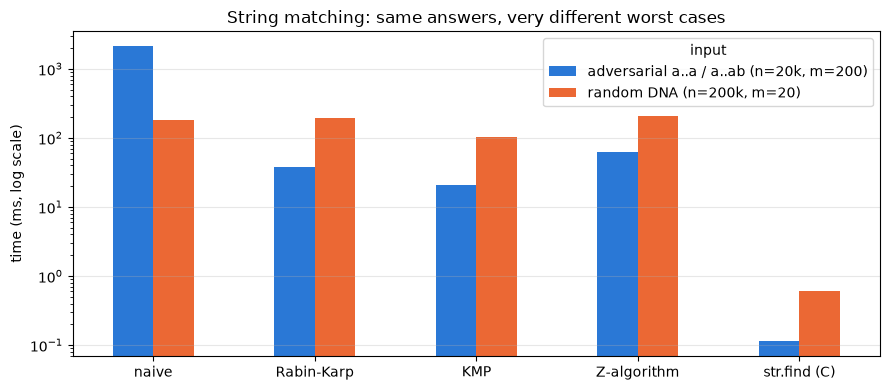

In [17]:
random.seed(7)
dna = "".join(random.choice("acgt") for _ in range(200_000))
cases = {
    "random DNA (n=200k, m=20)": (dna, dna[123_456:123_476]),
    "adversarial a..a / a..ab (n=20k, m=200)": ("a" * 20_000, "a" * 199 + "b"),
}
rows = []
for case, (text, pat) in cases.items():
    ref = None
    for name, fn in MATCHERS.items():
        secs, res = best_time(fn, text, pat, repeat=1 if name == "naive" else 3)
        ref = res if ref is None else ref
        assert res == ref
        rows.append({"input": case, "algorithm": name, "ms": secs * 1000, "matches": len(res)})
bench = pd.DataFrame(rows)
print(bench.pivot(index="algorithm", columns="input", values="ms").round(2).loc[list(MATCHERS)])

fig, ax = plt.subplots(figsize=(9, 4))
piv = bench.pivot(index="algorithm", columns="input", values="ms").loc[list(MATCHERS)]
piv.plot.bar(ax=ax, logy=True, color=[COLORS["blue"], COLORS["orange"]], rot=0)
ax.set_ylabel("time (ms, log scale)"); ax.set_xlabel("")
ax.set_title("String matching: same answers, very different worst cases")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

**What just happened?** Read the table and the chart together:

- On **random text** the naive method stays within a small factor of KMP, Z and Rabin-Karp (sometimes faster, sometimes slower, depending on the run), because most windows fail on the first or second character. All pure-Python versions are far slower than the C implementation of `str.find`.
- On the **adversarial** input naive search does about $n\cdot m$ comparisons and becomes the slowest by a wide margin, while KMP, Z and Rabin-Karp stay linear. This is the whole point of the linear-time algorithms: a **guaranteed** worst case.
- `str.find` is fastest everywhere: in real code use the built-in (or `re`), and use KMP/Z/Rabin-Karp when you need something the built-in cannot do, such as matching over a **stream** (KMP keeps only `j`), many patterns at once (Rabin-Karp with a set of hashes, or Aho-Corasick, which is "KMP on a trie"), or rolling hashes of every window (deduplication, plagiarism detection).

| algorithm | preprocessing | search (worst) | extra space | notes |
|---|---|---|---|---|
| naive | none | $O(nm)$ | $O(1)$ | fine on random text |
| Rabin-Karp | $O(m)$ | $O(nm)$ worst, $O(n+m)$ expected | $O(1)$ | multi-pattern, rolling hashes |
| KMP | $O(m)$ | $O(n+m)$ | $O(m)$ | streaming, never moves backwards in the text |
| Z-algorithm | – | $O(n+m)$ | $O(n+m)$ | Z-array answers many other string questions |
| Manacher | – | $O(n)$ | $O(n)$ | longest palindromic substring |

> 🎓 **Exam / interview tip:** be ready to compute an LPS array or a Z-array by hand (a common exam question) and to explain *why* KMP is linear: the number of times `j` decreases is at most the number of times it increased, which is at most $n$.

---
## 3. Range queries

> **In plain English:** pre-compute totals (or minimums) for blocks of an array so any "between a and b" question needs only a few blocks, even while values change.

**Range query problem** — keep an array $a[0..n-1]$ and answer questions about a contiguous range $a[l..r]$ (sum, minimum, maximum, ...), possibly mixed with **updates**. Analogy: a shop's daily sales ledger; the manager asks "total sales from day 40 to day 90?" while new corrections keep arriving.

| approach | build | range query | point update | range update |
|---|---|---|---|---|
| plain array | $O(1)$ | $O(n)$ | $O(1)$ | $O(n)$ |
| prefix sums `pre[i] = a[0]+...+a[i-1]` | $O(n)$ | $O(1)$ | $O(n)$ (rebuild) | $O(n)$ |
| **Fenwick tree (BIT)** | $O(n)$ | $O(\log n)$ | $O(\log n)$ | $O(\log n)$ with a trick |
| **segment tree** | $O(n)$ | $O(\log n)$ | $O(\log n)$ | $O(\log n)$ with **lazy propagation** |
| **sparse table** (static, min/max) | $O(n\log n)$ | $O(1)$ | not supported | not supported |

### 3.1 Segment tree

**Segment tree** — a binary tree in which the root covers the whole array `[0, n-1]`, each node covering `[lo, hi]` has two children covering `[lo, mid]` and `[mid+1, hi]`, and every node stores the **sum** of its range. Stored in a list with the root at index 1 and the children of node `k` at `2k` and `2k+1` (like a heap); a list of size $4n$ is always enough.

A query `[l, r]` splits into at most about $2\log_2 n$ nodes that lie completely inside the range ("canonical" nodes), so it costs $O(\log n)$. A point update changes one leaf and the $\log_2 n$ ancestors above it.

sum(2..6) = 20 | check: 20 | canonical nodes used: [(2, 3), (4, 5), (6, 6)]


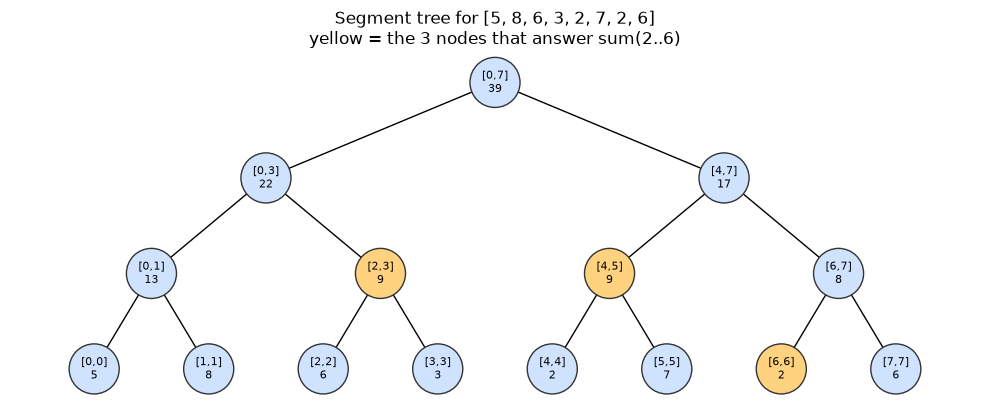

In [18]:
class SegmentTree:
    # Range-sum segment tree with point assignment. Node k covers [lo, hi]; children are 2k and 2k+1.
    def __init__(self, arr):
        self.n = len(arr)
        self.sum = [0] * (4 * self.n)
        self.visited = []                                  # nodes touched by the last query (for teaching)
        self._build(1, 0, self.n - 1, arr)

    def _build(self, k, lo, hi, arr):
        if lo == hi:                                       # leaf: one array element
            self.sum[k] = arr[lo]
            return
        mid = (lo + hi) // 2
        self._build(2 * k, lo, mid, arr)
        self._build(2 * k + 1, mid + 1, hi, arr)
        self.sum[k] = self.sum[2 * k] + self.sum[2 * k + 1] # parent = sum of the two children

    def query(self, l, r):                                 # sum of arr[l..r], inclusive
        self.visited = []
        return self._query(1, 0, self.n - 1, l, r)

    def _query(self, k, lo, hi, l, r):
        if r < lo or hi < l:                               # no overlap
            return 0
        if l <= lo and hi <= r:                            # node completely inside the query: use it whole
            self.visited.append((lo, hi))
            return self.sum[k]
        mid = (lo + hi) // 2                               # partial overlap: ask both children
        return self._query(2 * k, lo, mid, l, r) + self._query(2 * k + 1, mid + 1, hi, l, r)

    def update(self, idx, value):                          # arr[idx] = value
        self._update(1, 0, self.n - 1, idx, value)

    def _update(self, k, lo, hi, idx, value):
        if lo == hi:
            self.sum[k] = value
            return
        mid = (lo + hi) // 2
        if idx <= mid:
            self._update(2 * k, lo, mid, idx, value)
        else:
            self._update(2 * k + 1, mid + 1, hi, idx, value)
        self.sum[k] = self.sum[2 * k] + self.sum[2 * k + 1] # recompute on the way back up


arr = [5, 8, 6, 3, 2, 7, 2, 6]
st = SegmentTree(arr)
print("sum(2..6) =", st.query(2, 6), "| check:", sum(arr[2:7]), "| canonical nodes used:", st.visited)

edges, labels, used = [], {}, set(st.visited)
def collect_seg(k, lo, hi):
    labels[k] = f"[{lo},{hi}]\n{st.sum[k]}"
    if lo < hi:
        mid = (lo + hi) // 2
        edges.extend([(k, 2 * k), (k, 2 * k + 1)])
        collect_seg(2 * k, lo, mid); collect_seg(2 * k + 1, mid + 1, hi)
collect_seg(1, 0, len(arr) - 1)
highlight = {k for k, txt in labels.items() if tuple(map(int, txt.split("\n")[0][1:-1].split(","))) in used}
fig, ax = plt.subplots(figsize=(10, 4.2))
draw_tree(edges, 1, labels, ax, f"Segment tree for {arr}\nyellow = the 3 nodes that answer sum(2..6)", highlight=highlight, node_size=1300, font_size=8)
plt.tight_layout(); plt.show()

**What just happened?** The query `sum(2..6)` did not add five numbers; it added three stored node values: `[2,3] = 9`, `[4,5] = 9` and `[6,6] = 2`, giving 20. On an array of a million elements the same query would still use only about 40 nodes.

### 3.2 Lazy propagation: range updates in $O(\log n)$

"Add 10 to every element of `a[l..r]`" would touch up to $n$ leaves. **Lazy propagation** stops at the canonical nodes instead: it updates their sums (`sum += add × length`) and writes a note `lazy[k] += add` meaning *"my children still owe this addition"*. The note is **pushed down** to the children only when a later operation needs to go below that node. Analogy: a manager who receives "give everyone in your department a raise" updates the department total immediately and tells individual employees only when somebody asks about them.

In [19]:
class LazySegmentTree(SegmentTree):
    # Range-sum segment tree with range add (lazy propagation) and point assignment
    def __init__(self, arr):
        self.lazy = [0] * (4 * len(arr))                   # pending additions for the children of each node
        super().__init__(arr)

    def _apply(self, k, lo, hi, add):
        self.sum[k] += add * (hi - lo + 1)                 # every element of [lo, hi] grows by add
        self.lazy[k] += add                                # remember to pass it on to the children later

    def _push(self, k, lo, hi):
        if self.lazy[k]:
            mid = (lo + hi) // 2
            self._apply(2 * k, lo, mid, self.lazy[k])
            self._apply(2 * k + 1, mid + 1, hi, self.lazy[k])
            self.lazy[k] = 0

    def range_add(self, l, r, add, k=1, lo=0, hi=None):
        hi = self.n - 1 if hi is None else hi
        if r < lo or hi < l:
            return
        if l <= lo and hi <= r:                            # canonical node: stop here, leave a lazy note
            self._apply(k, lo, hi, add)
            return
        self._push(k, lo, hi)                              # going deeper: settle old notes first
        mid = (lo + hi) // 2
        self.range_add(l, r, add, 2 * k, lo, mid)
        self.range_add(l, r, add, 2 * k + 1, mid + 1, hi)
        self.sum[k] = self.sum[2 * k] + self.sum[2 * k + 1]

    def _query(self, k, lo, hi, l, r):
        if r < lo or hi < l:
            return 0
        if l <= lo and hi <= r:
            self.visited.append((lo, hi))
            return self.sum[k]
        self._push(k, lo, hi)                              # the only change vs. the plain tree
        mid = (lo + hi) // 2
        return self._query(2 * k, lo, mid, l, r) + self._query(2 * k + 1, mid + 1, hi, l, r)

    def _update(self, k, lo, hi, idx, value):
        if lo == hi:
            self.sum[k] = value
            return
        self._push(k, lo, hi)
        mid = (lo + hi) // 2
        if idx <= mid:
            self._update(2 * k, lo, mid, idx, value)
        else:
            self._update(2 * k + 1, mid + 1, hi, idx, value)
        self.sum[k] = self.sum[2 * k] + self.sum[2 * k + 1]


lst = LazySegmentTree(arr)
lst.range_add(1, 5, 10)
print("after adding 10 to a[1..5]: sum(0..7) =", lst.query(0, 7), "| sum(4..6) =", lst.query(4, 6))
check = [v + 10 if 1 <= i <= 5 else v for i, v in enumerate(arr)]
assert lst.query(0, 7) == sum(check) and lst.query(4, 6) == sum(check[4:7])

# Brute-force verification: random mixes of range add, point assignment and range sum
for trial in range(60):
    n = random.randint(1, 40)
    ref = [random.randint(-50, 50) for _ in range(n)]
    seg = LazySegmentTree(ref)
    for _ in range(200):
        l = random.randrange(n); r = random.randrange(l, n); op = random.random()
        if op < 0.35:
            add = random.randint(-9, 9); seg.range_add(l, r, add)
            for i in range(l, r + 1):
                ref[i] += add
        elif op < 0.55:
            v = random.randint(-50, 50); seg.update(l, v); ref[l] = v
        else:
            assert seg.query(l, r) == sum(ref[l:r + 1])
        CHECKS["lazy segment tree"] += 1
print("lazy segment tree matches a plain list on", CHECKS["lazy segment tree"], "random operations")

after adding 10 to a[1..5]: sum(0..7) = 89 | sum(4..6) = 31


lazy segment tree matches a plain list on 12000 random operations


> ⚠️ **Common mistake:** forgetting to `_push` before recursing into the children (in `query`, `update` **and** `range_add`). The children then miss pending additions and you get answers that are only sometimes wrong, which is exactly why we test against a brute force.

### 3.3 Fenwick tree (binary indexed tree, BIT)

A **Fenwick tree** (Fenwick, 1994) supports prefix sums and point additions in $O(\log n)$ with **one array and no tree pointers**, using a bit trick. With 1-based indices, cell `i` stores the sum of the `lowbit(i)` elements ending at `i`, where **`lowbit(i) = i & -i`** is the value of the lowest set bit of `i`.

- `prefix_sum(i)`: add `tree[i]`, then jump to `i - lowbit(i)` (removes the lowest bit) until 0.
- `add(i, delta)`: add to `tree[i]`, then jump to `i + lowbit(i)` (the next cell whose block covers `i`).

Each jump clears or carries one bit, so both take at most $\lfloor\log_2 n\rfloor + 1$ steps.

In [20]:
fenwick_table = pd.DataFrame(
    [{"i": i, "binary": format(i, "04b"), "lowbit(i) = i & -i": i & -i, "tree[i] covers a[...]": f"{i - (i & -i) + 1}..{i}"}
     for i in range(1, 13)])
fenwick_table.set_index("i").T

i,1,2,3,4,5,6,7,8,9,10,11,12
binary,0001,0010,0011,0100,0101,0110,0111,1000,1001,1010,1011,1100
lowbit(i) = i & -i,1,2,1,4,1,2,1,8,1,2,1,4
tree[i] covers a[...],1..1,1..2,3..3,1..4,5..5,5..6,7..7,1..8,9..9,9..10,11..11,9..12


In [21]:
class FenwickTree:
    def __init__(self, n):
        self.n = n
        self.tree = [0] * (n + 1)                # index 0 unused: 1-based internally

    @classmethod
    def from_list(cls, arr):                     # O(n) build: push each cell's total to its parent once
        ft = cls(len(arr))
        for i, v in enumerate(arr, start=1):
            ft.tree[i] += v
            parent = i + (i & -i)
            if parent <= ft.n:
                ft.tree[parent] += ft.tree[i]
        return ft

    def add(self, idx, delta):                   # a[idx] += delta   (idx is 0-based for the user)
        i = idx + 1
        while i <= self.n:
            self.tree[i] += delta
            i += i & -i                          # move to the next block that contains idx

    def prefix_sum(self, count):                 # a[0] + ... + a[count-1]
        s, i = 0, count
        while i > 0:
            s += self.tree[i]
            i -= i & -i                          # drop the lowest set bit
        return s

    def range_sum(self, l, r):                   # a[l] + ... + a[r]
        return self.prefix_sum(r + 1) - self.prefix_sum(l)


ft = FenwickTree.from_list(arr)
print("Fenwick sum(2..6) =", ft.range_sum(2, 6))
for trial in range(60):
    n = random.randint(1, 50)
    ref = [random.randint(-50, 50) for _ in range(n)]
    f = FenwickTree.from_list(ref)
    for _ in range(200):
        l = random.randrange(n); r = random.randrange(l, n)
        if random.random() < 0.4:
            d = random.randint(-9, 9); f.add(l, d); ref[l] += d
        else:
            assert f.range_sum(l, r) == sum(ref[l:r + 1])
        CHECKS["Fenwick tree"] += 1
print("Fenwick tree matches a plain list on", CHECKS["Fenwick tree"], "random operations")

Fenwick sum(2..6) = 20


Fenwick tree matches a plain list on 12000 random operations


### 3.4 Sparse table for range-minimum queries (static data)

If the array **never changes** and the operation is **idempotent** (`min(x, x) = x`, also true for `max` and `gcd`, but not for `+`), we can answer queries in $O(1)$.

**Sparse table** — `table[j][i] = min(a[i .. i + 2^j - 1])`, built level by level: `table[j][i] = min(table[j-1][i], table[j-1][i + 2^(j-1)])`. A query `[l, r]` takes $k = \lfloor\log_2(r-l+1)\rfloor$ and the minimum of two overlapping blocks of length $2^k$: one starting at `l`, one ending at `r`. Overlap is harmless for `min`.

Build $O(n\log n)$ time and space; query $O(1)$.

In [22]:
class SparseTable:
    def __init__(self, arr):
        n = len(arr)
        self.log = [0] * (n + 1)
        for i in range(2, n + 1):
            self.log[i] = self.log[i // 2] + 1          # floor(log2(i)) without floating point
        self.table = [list(arr)]                        # level 0: blocks of length 1
        j = 1
        while (1 << j) <= n:
            prev, half = self.table[-1], 1 << (j - 1)
            self.table.append([min(prev[i], prev[i + half]) for i in range(n - (1 << j) + 1)])
            j += 1

    def query(self, l, r):                              # min(a[l..r]) in O(1)
        k = self.log[r - l + 1]
        return min(self.table[k][l], self.table[k][r - (1 << k) + 1])


sp = SparseTable(arr)
print("levels:", [len(level) for level in sp.table], "| min(a[2..6]) =", sp.query(2, 6), "| check:", min(arr[2:7]))
for trial in range(200):
    data = [random.randint(-100, 100) for _ in range(random.randint(1, 60))]
    s = SparseTable(data)
    for _ in range(30):
        l = random.randrange(len(data)); r = random.randrange(l, len(data))
        assert s.query(l, r) == min(data[l:r + 1])
        CHECKS["sparse table RMQ"] += 1
print("sparse table matches min() on", CHECKS["sparse table RMQ"], "random queries")

levels: [8, 7, 5, 1] | min(a[2..6]) = 2 | check: 2


sparse table matches min() on 6000 random queries


### 3.5 Benchmark: a mixed workload of updates and range sums

1,000 operations (half point updates, half range-sum queries) on arrays of growing size $n$; we time the build and the operations separately. The plain list answers each query with Python's C-level `sum` over a slice; the prefix-sum array rebuilds itself (with C-level `itertools.accumulate`) after every update.

In [23]:
from itertools import accumulate

# Each structure = (build function, function that runs the operations on the built structure)
def plain_ops(a, ops):
    out = 0
    for kind, x, y in ops:
        if kind == "upd": a[x] += y
        else: out += sum(a[x:y + 1])                      # O(n) query (C-level sum)
    return out

def prefix_ops(state, ops):
    a, pre = state
    out = 0
    for kind, x, y in ops:
        if kind == "upd":
            a[x] += y; pre = [0, *accumulate(a)]          # O(n) rebuild after every update
        else:
            out += pre[y + 1] - pre[x]                    # O(1) query
    return out

def fenwick_ops(f, ops):
    out = 0
    for kind, x, y in ops:
        if kind == "upd": f.add(x, y)
        else: out += f.range_sum(x, y)
    return out

def segment_ops(state, ops):
    s, cur = state                                        # the plain tree does assignments, so track values
    out = 0
    for kind, x, y in ops:
        if kind == "upd": cur[x] += y; s.update(x, cur[x])
        else: out += s.query(x, y)
    return out

STRUCTURES = {
    "plain list":   (lambda a: list(a),                         plain_ops),
    "prefix sums":  (lambda a: (list(a), [0, *accumulate(a)]),  prefix_ops),
    "Fenwick":      (FenwickTree.from_list,                     fenwick_ops),
    "segment tree": (lambda a: (SegmentTree(a), list(a)),       segment_ops),
}

rows = []
rng = random.Random(1)
for n in (1_000, 10_000, 50_000):
    a = [rng.randint(0, 100) for _ in range(n)]
    ops = []
    for _ in range(1_000):
        if rng.random() < 0.5:
            ops.append(("upd", rng.randrange(n), rng.randint(-5, 5)))
        else:
            l = rng.randrange(n); ops.append(("qry", l, rng.randrange(l, n)))
    answers = set()
    for name, (build, run) in STRUCTURES.items():
        t0 = time.perf_counter(); state = build(a); t1 = time.perf_counter()
        res = run(state, ops); t2 = time.perf_counter()
        answers.add(res)
        rows.append({"n": n, "structure": name, "build ms": round((t1 - t0) * 1000, 1), "ops ms": round((t2 - t1) * 1000, 1)})
    assert len(answers) == 1                              # all four structures computed the same total
res_df = pd.DataFrame(rows)
rq = res_df.pivot(index="structure", columns="n", values="ops ms").loc[list(STRUCTURES)]
print("milliseconds for 1,000 mixed operations (build NOT included):")
print(rq)
print("\nbuild time at n = 50,000 (ms):", res_df[res_df.n == 50_000].set_index("structure")["build ms"].to_dict())

milliseconds for 1,000 mixed operations (build NOT included):
n             1000    10000   50000
structure                          
plain list      3.4    28.8   423.8
prefix sums    75.8  1140.5  3709.7
Fenwick         3.4     7.0    20.5
segment tree   13.0    23.4   135.9

build time at n = 50,000 (ms): {'plain list': 3.0, 'prefix sums': 10.4, 'Fenwick': 70.1, 'segment tree': 179.1}


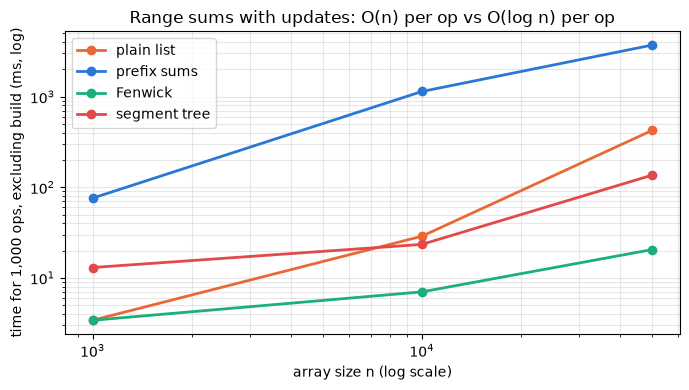

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
for (name, row), c in zip(rq.iterrows(), [COLORS["orange"], COLORS["blue"], COLORS["green"], COLORS["red"]]):
    ax.loglog(row.index, row.values, marker="o", lw=2, label=name, color=c)
ax.set_xlabel("array size n (log scale)"); ax.set_ylabel("time for 1,000 ops, excluding build (ms, log)")
ax.set_title("Range sums with updates: O(n) per op vs O(log n) per op")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

**What just happened?** We timed the 1,000 operations separately from the one-off build. The lines for the plain list and the prefix sums grow roughly linearly with $n$ (each of their slow operations is $O(n)$), while the Fenwick tree and the segment tree grow much more slowly. In theory their cost is $O(\log n)$ per operation (going from 1,000 to 50,000 elements adds only about 6 levels); in practice they grow somewhat faster than that because a larger array no longer fits in the CPU's fast caches, and because short timings are noisy. Python's C-level `sum` and `accumulate` make the plain approaches look good for small arrays; for larger $n$, or in a compiled language, the logarithmic structures win by a larger margin. The Fenwick tree is shorter, faster and smaller than the segment tree; the segment tree is more flexible (min/max/gcd, lazy range updates, custom merge functions). Both builds are $O(n)$ and happen once.

> 🎓 **Exam / interview tip:** "count inversions", "number of smaller elements to the right" and "dynamic ranking" are Fenwick-tree problems; "range assign / range add with range sum/min" calls for a segment tree with lazy propagation; "many range-min queries on fixed data" calls for a sparse table.

---
## 4. Number theory for programmers

> **In plain English:** fast tricks with whole numbers and remainders ("clock arithmetic") that power hashing and encryption.

### 4.1 GCD and LCM: Euclid's algorithm

The **greatest common divisor** $\gcd(a, b)$ is the largest integer dividing both $a$ and $b$; the **least common multiple** $\mathrm{lcm}(a,b) = \dfrac{|a\cdot b|}{\gcd(a,b)}$.

**Euclid's algorithm** (about 300 BC) uses $\gcd(a, b) = \gcd(b, a \bmod b)$ and $\gcd(a, 0) = a$. It takes $O(\log \min(a, b))$ steps (the worst case is consecutive Fibonacci numbers, by Lamé's theorem).

**Extended Euclid** also finds integers $x, y$ with **Bézout's identity** $a x + b y = \gcd(a, b)$. We need this for modular inverses (section 4.5) and RSA.

Hand trace of $\gcd(240, 46)$:

| a | b | a mod b |
|---|---|---|
| 240 | 46 | 10 |
| 46 | 10 | 6 |
| 10 | 6 | 4 |
| 6 | 4 | 2 |
| 4 | 2 | 0 |
| 2 | 0 | – → gcd = **2** |

In [25]:
def gcd(a, b):
    a, b = abs(a), abs(b)
    while b:
        a, b = b, a % b              # gcd(a, b) = gcd(b, a mod b)
    return a

def lcm(a, b):
    return 0 if a == 0 or b == 0 else abs(a * b) // gcd(a, b)

def extended_gcd(a, b, trace=None):
    # Returns (g, x, y) with a*x + b*y == g == gcd(a, b). Iterative version keeps two Bezout rows.
    old_r, r = a, b
    old_x, x = 1, 0
    old_y, y = 0, 1
    while r:
        q = old_r // r
        if trace is not None:
            trace.append((old_r, r, q, old_x, old_y))
        old_r, r = r, old_r - q * r              # the same steps as Euclid ...
        old_x, x = x, old_x - q * x              # ... while tracking how each remainder
        old_y, y = y, old_y - q * y              #     is written as a*x + b*y
    return old_r, old_x, old_y

tr = []
g, x, y = extended_gcd(240, 46, tr)
print(pd.DataFrame(tr, columns=["r_prev", "r", "q", "x_prev", "y_prev"]).to_string(index=False))
print(f"\ngcd(240, 46) = {g},  240*({x}) + 46*({y}) = {240 * x + 46 * y},  lcm = {lcm(240, 46)}")

for _ in range(3000):
    a, b = random.randint(0, 10**12), random.randint(0, 10**12)
    g, x, y = extended_gcd(a, b)
    assert g == gcd(a, b) == math.gcd(a, b) and a * x + b * y == g and lcm(a, b) == math.lcm(a, b)
    CHECKS["gcd / extended gcd / lcm"] += 1

 r_prev  r  q  x_prev  y_prev
    240 46  5       1       0
     46 10  4       0       1
     10  6  1       1      -5
      6  4  1      -4      21
      4  2  2       5     -26

gcd(240, 46) = 2,  240*(-9) + 46*(47) = 2,  lcm = 5520


### 4.2 The Sieve of Eratosthenes

A **prime** is an integer $p \ge 2$ whose only positive divisors are 1 and $p$. To list all primes up to $n$: write the numbers $2..n$; take the smallest unmarked number $p$ (it is prime) and cross out its multiples starting at $p^2$ (smaller multiples were already crossed out by smaller primes); stop when $p^2 > n$.

```
2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20      n = 20
2 3 x 5 x 7 x 9  x 11  x 13  x 15  x 17  x 19  x       cross multiples of 2 from 4
2 3 x 5 x 7 x x  x 11  x 13  x  x  x 17  x 19  x       cross multiples of 3 from 9; 5*5 > 20: stop
primes: 2 3 5 7 11 13 17 19
```

Time $O(n \log\log n)$ (sum of $n/p$ over primes $p$), space $O(n)$. Checking each number by trial division would cost $O(n\sqrt{n})$.

In [26]:
def sieve(n):
    is_prime = bytearray([1]) * (n + 1)          # 1 byte per number; bytearray is compact and fast
    is_prime[0:2] = b"\x00\x00"                  # 0 and 1 are not prime
    p = 2
    while p * p <= n:
        if is_prime[p]:
            is_prime[p * p::p] = bytes(len(range(p * p, n + 1, p)))   # cross out p*p, p*p+p, ... in one slice
        p += 1
    return [i for i in range(n + 1) if is_prime[i]]

def is_prime_trial(n):
    if n < 2:
        return False
    return all(n % d for d in range(2, math.isqrt(n) + 1))     # only need divisors up to sqrt(n)

print("primes up to 50:", sieve(50))
assert sieve(20_000) == [i for i in range(20_001) if is_prime_trial(i)]
CHECKS["sieve of Eratosthenes"] += 20_001

N = 2_000_000
secs, primes = best_time(sieve, N, repeat=1)
print(f"sieve({N:,}) found {len(primes):,} primes in {secs:.2f} s")

primes up to 50: [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47]


sieve(2,000,000) found 148,933 primes in 0.44 s


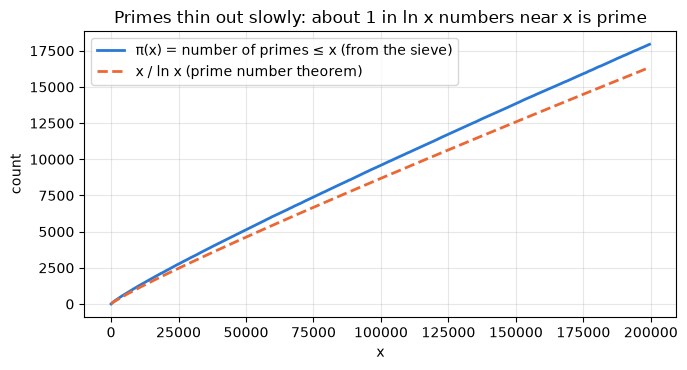

In [27]:
xs = np.arange(10, 200_001, 500)
pi_x = np.searchsorted(np.array(primes), xs, side="right")   # pi(x) = number of primes <= x
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(xs, pi_x, lw=2, color=COLORS["blue"], label="π(x) = number of primes ≤ x (from the sieve)")
ax.plot(xs, xs / np.log(xs), lw=2, ls="--", color=COLORS["orange"], label="x / ln x (prime number theorem)")
ax.set_xlabel("x"); ax.set_ylabel("count"); ax.set_title("Primes thin out slowly: about 1 in ln x numbers near x is prime")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 4.3 Prime factorisation

Every integer $n \ge 2$ is a product of primes in exactly one way (the **fundamental theorem of arithmetic**), e.g. $360 = 2^3\cdot 3^2\cdot 5$.

- **Trial division:** divide by $d = 2, 3, 4, \dots$ while $d^2 \le n$; whatever is left above 1 is prime. $O(\sqrt{n})$.
- **Smallest-prime-factor (SPF) sieve:** a modified sieve stores `spf[i]`, then any $i \le N$ factors in $O(\log i)$ by repeatedly dividing by `spf[i]`. Best when you factor many numbers.

In [28]:
def factorize(n):
    factors, d = Counter(), 2
    while d * d <= n:
        while n % d == 0:
            factors[d] += 1
            n //= d
        d += 1 if d == 2 else 2                    # after 2, only odd candidates
    if n > 1:
        factors[n] += 1                            # leftover > 1 is a prime factor
    return dict(factors)

def spf_sieve(n):
    spf = list(range(n + 1))                       # spf[i] = smallest prime factor of i
    for p in range(2, math.isqrt(n) + 1):
        if spf[p] == p:                            # p is prime
            for multiple in range(p * p, n + 1, p):
                if spf[multiple] == multiple:
                    spf[multiple] = p
    return spf

def factorize_spf(n, spf):
    factors = Counter()
    while n > 1:
        factors[spf[n]] += 1
        n //= spf[n]
    return dict(factors)

print("360 =", factorize(360), "| 2**31 - 1 =", factorize(2**31 - 1), "| 600851475143 =", factorize(600851475143))
SPF = spf_sieve(30_000)
for n in range(2, 30_001):
    f = factorize(n)
    assert f == factorize_spf(n, SPF) and math.prod(p**e for p, e in f.items()) == n and all(is_prime_trial(p) for p in f)
CHECKS["prime factorisation"] += 29_999

360 = {2: 3, 3: 2, 5: 1} | 2**31 - 1 = {2147483647: 1} | 600851475143 = {71: 1, 839: 1, 1471: 1, 6857: 1}


### 4.4 Modular arithmetic and fast exponentiation

**Modular arithmetic** is "clock arithmetic": $a \bmod m$ is the remainder after dividing by $m$, and $a \equiv b \pmod m$ means $m$ divides $a-b$. On a 12-hour clock, $9 + 5 \equiv 2 \pmod{12}$. Addition, subtraction and multiplication can be reduced at any time:

$$(a + b) \bmod m = ((a \bmod m) + (b \bmod m)) \bmod m, \qquad (a \cdot b) \bmod m = ((a \bmod m)(b \bmod m)) \bmod m$$

so numbers never grow beyond $m^2$. **Division is different:** it needs a modular inverse (4.5).

**Fast (binary) modular exponentiation** computes $a^e \bmod m$ with $O(\log e)$ multiplications instead of $e - 1$: write $e$ in binary and square repeatedly. Example $3^{13}$, $13 = 1101_2$: $3^{13} = 3^{8}\cdot 3^{4}\cdot 3^{1}$.

In [29]:
def mod_pow(base, exp, mod, trace=None):
    result, base = 1 % mod, base % mod
    while exp > 0:
        if exp & 1:                                 # lowest bit is 1: this power of base is part of the product
            result = result * base % mod
        if trace is not None:
            trace.append((exp, exp & 1, base, result))
        base = base * base % mod                    # base^(2^k) -> base^(2^(k+1))
        exp >>= 1                                   # move to the next bit
    return result

tr = []
print("3^13 mod 1000 =", mod_pow(3, 13, 1000, tr), "| check:", 3**13 % 1000)
print(pd.DataFrame(tr, columns=["exp (remaining)", "low bit", "base^(2^k) mod m", "result so far"]).to_string(index=False))

for _ in range(3000):
    a, e, m = random.randint(0, 10**18), random.randint(0, 10**18), random.randint(1, 10**12)
    assert mod_pow(a, e, m) == pow(a, e, m)          # Python's built-in 3-argument pow is the reference
    CHECKS["fast modular exponentiation"] += 1
print("\n2^(10^18) mod (10^9+7) =", mod_pow(2, 10**18, 10**9 + 7), "(about 60 squarings, not 10^18 multiplications)")

3^13 mod 1000 = 323 | check: 323
 exp (remaining)  low bit  base^(2^k) mod m  result so far
              13        1                 3              3
               6        0                 9              3
               3        1                81            243
               1        1               561            323



2^(10^18) mod (10^9+7) = 719476260 (about 60 squarings, not 10^18 multiplications)


### 4.5 The modular inverse

The **modular inverse** of $a$ modulo $m$ is the number $a^{-1}$ with $a \cdot a^{-1} \equiv 1 \pmod m$. It exists **if and only if** $\gcd(a, m) = 1$. Two ways to compute it:

1. **Extended Euclid:** from $a x + m y = 1$ we get $a x \equiv 1$, so $a^{-1} = x \bmod m$. Works for any $m$. $O(\log m)$.
2. **Fermat's little theorem** (only when $m = p$ is prime): $a^{p-1} \equiv 1 \pmod p$ for $p \nmid a$, so $a^{-1} \equiv a^{p-2} \pmod p$. $O(\log p)$.

Example: $3^{-1} \bmod 11 = 4$ because $3 \cdot 4 = 12 \equiv 1$.

In [30]:
def mod_inverse(a, m):
    g, x, _ = extended_gcd(a % m, m)
    if g != 1:
        raise ValueError(f"{a} has no inverse modulo {m} (gcd = {g})")
    return x % m

def mod_inverse_fermat(a, p):                      # p must be prime and not divide a
    return mod_pow(a, p - 2, p)

print("3^-1 mod 11 =", mod_inverse(3, 11), "| Fermat:", mod_inverse_fermat(3, 11), "| built-in pow(3, -1, 11):", pow(3, -1, 11))
try:
    mod_inverse(6, 9)
except ValueError as err:                         # deliberate error: 6 and 9 share the factor 3
    print("expected error ->", err)

P = 1_000_000_007
for _ in range(3000):
    m = random.randint(2, 10**9)
    a = random.randint(1, 10**9)
    if math.gcd(a, m) == 1:
        assert a * mod_inverse(a, m) % m == 1 and mod_inverse(a, m) == pow(a, -1, m)
    a = random.randint(1, P - 1)
    assert mod_inverse_fermat(a, P) == mod_inverse(a, P)
    CHECKS["modular inverse"] += 1

3^-1 mod 11 = 4 | Fermat: 4 | built-in pow(3, -1, 11): 4
expected error -> 6 has no inverse modulo 9 (gcd = 3)


### 4.6 Euler's totient function

**Euler's totient** $\varphi(n)$ counts the integers in $1..n$ that are **coprime** to $n$ ($\gcd = 1$). With $n = p_1^{e_1}\cdots p_k^{e_k}$:

$$\varphi(n) = n\prod_{p \mid n}\left(1 - \frac{1}{p}\right), \qquad \text{e.g. } \varphi(36) = 36\cdot\tfrac12\cdot\tfrac23 = 12.$$

For a prime, $\varphi(p) = p-1$; for two different primes, $\varphi(pq) = (p-1)(q-1)$ (this is the heart of RSA). **Euler's theorem:** if $\gcd(a, n) = 1$ then $a^{\varphi(n)} \equiv 1 \pmod n$ (Fermat's little theorem is the special case $n = p$). A sieve computes $\varphi$ for all numbers up to $N$ in $O(N\log\log N)$.

In [31]:
def phi(n):
    result = n
    for p in factorize(n) if n > 1 else {}:
        result -= result // p                       # multiply by (1 - 1/p) using integers only
    return result

def phi_sieve(n):
    ph = list(range(n + 1))
    for p in range(2, n + 1):
        if ph[p] == p:                              # p untouched so far -> p is prime
            for k in range(p, n + 1, p):
                ph[k] -= ph[k] // p
    return ph

def phi_brute(n):
    return sum(1 for k in range(1, n + 1) if math.gcd(k, n) == 1)

print("phi(36) =", phi(36), "| phi(13) =", phi(13), "| phi(61*53) =", phi(61 * 53), "= 60*52 =", 60 * 52)
PH = phi_sieve(3000)
for n in range(1, 3001):
    assert phi(n) == PH[n] == phi_brute(n)
    a = random.randint(1, 10**6)
    if math.gcd(a, n) == 1:
        assert mod_pow(a, phi(n), n) == 1 % n                  # Euler's theorem
    CHECKS["Euler's totient (+ Euler's theorem)"] += 1

phi(36) = 12 | phi(13) = 12 | phi(61*53) = 3120 = 60*52 = 3120


### 4.7 $\binom{n}{r} \bmod p$

Counting problems quickly produce astronomically large numbers, so contests and many probability computations ask for $\binom{n}{r} = \frac{n!}{r!\,(n-r)!} \bmod p$ with a prime $p$ such as $10^9+7$. We cannot divide modulo $p$, but we can **multiply by inverses**:

$$\binom{n}{r} \equiv n!\cdot (r!)^{-1}\cdot ((n-r)!)^{-1} \pmod p.$$

Pre-compute `fact[i]` and `inv_fact[i]` once in $O(N)$ (one Fermat inverse, then `inv_fact[i-1] = inv_fact[i] * i`), after which every query is $O(1)$. This requires $n < p$; for huge $n$ and a small prime, **Lucas' theorem** splits $n$ and $r$ into base-$p$ digits: $\binom{n}{r} \equiv \prod_i \binom{n_i}{r_i} \pmod p$.

In [32]:
class BinomialModP:
    def __init__(self, max_n, p=1_000_000_007):
        self.p = p
        self.fact = [1] * (max_n + 1)
        for i in range(1, max_n + 1):
            self.fact[i] = self.fact[i - 1] * i % p
        self.inv_fact = [1] * (max_n + 1)
        self.inv_fact[max_n] = mod_pow(self.fact[max_n], p - 2, p)   # one Fermat inverse ...
        for i in range(max_n, 0, -1):
            self.inv_fact[i - 1] = self.inv_fact[i] * i % p           # ... then all the others for free

    def ncr(self, n, r):
        if r < 0 or r > n:
            return 0
        return self.fact[n] * self.inv_fact[r] % self.p * self.inv_fact[n - r] % self.p


def ncr_lucas(n, r, p):                          # p a (small) prime, n can be huge
    result = 1
    while n or r:
        ni, ri = n % p, r % p                    # current base-p digits
        if ri > ni:
            return 0
        result = result * math.comb(ni, ri) % p
        n //= p; r //= p
    return result

B = BinomialModP(5000)
print("C(5000, 2500) mod 1e9+7 =", B.ncr(5000, 2500), "| C(10, 3) =", B.ncr(10, 3))
for _ in range(2000):
    n = random.randint(0, 5000); r = random.randint(-2, n + 2)
    assert B.ncr(n, r) == (math.comb(n, r) % B.p if 0 <= r <= n else 0)
    n, r, p = random.randint(0, 10**6), random.randint(0, 2000), random.choice([2, 3, 5, 7, 13, 101])
    assert ncr_lucas(n, r, p) == math.comb(n, r) % p
    CHECKS["nCr mod p (+ Lucas)"] += 1

C(5000, 2500) mod 1e9+7 = 248346497 | C(10, 3) = 120


### 4.8 RSA in brief (textbook version)

**RSA** (Rivest, Shamir, Adleman, 1977) is a **public-key** cryptosystem: anyone can encrypt with the public key $(n, e)$, only the owner of the private key $d$ can decrypt. It uses everything in this section:

1. Pick two large primes $p, q$; compute $n = pq$ and $\varphi(n) = (p-1)(q-1)$.
2. Pick $e$ with $\gcd(e, \varphi(n)) = 1$ (commonly $65537$).
3. Compute $d = e^{-1} \bmod \varphi(n)$ with **extended Euclid**.
4. Encrypt $c = m^e \bmod n$, decrypt $m = c^d \bmod n$, both with **fast modular exponentiation**. It works because of **Euler's theorem**.

Security rests on the belief that **factoring** $n$ is hard when $p, q$ are huge (today: $n$ of at least 2048 bits). Classic toy example: $p = 61$, $q = 53$, $n = 3233$, $\varphi = 3120$, $e = 17$, $d = 2753$; the message $65$ encrypts to $2790$.

In [33]:
p, q, e = 61, 53, 17
n, ph = p * q, (p - 1) * (q - 1)
d = mod_inverse(e, ph)
message = 65
cipher = mod_pow(message, e, n)
decrypted = mod_pow(cipher, d, n)
print(f"n = {n}, phi(n) = {ph}, e = {e}, d = {d}  (check e*d mod phi = {e * d % ph})")
print(f"encrypt {message} -> {cipher};  decrypt {cipher} -> {decrypted}")
assert (n, ph, d, cipher, decrypted) == (3233, 3120, 2753, 2790, 65)

# Every message 0..n-1 round-trips, and an attacker who can factor n recovers d immediately
assert all(mod_pow(mod_pow(m, e, n), d, n) == m for m in range(n))
f = factorize(n)
print("attacker factors n:", f, "-> recovered d =", mod_inverse(e, math.prod(pr - 1 for pr in f)))
CHECKS["RSA round-trip"] += n

n = 3233, phi(n) = 3120, e = 17, d = 2753  (check e*d mod phi = 1)
encrypt 65 -> 2790;  decrypt 2790 -> 65
attacker factors n: {53: 1, 61: 1} -> recovered d = 2753


> ⚠️ **Common mistake (and a security warning):** the code above is **textbook RSA** for learning only. Real RSA uses random padding (OAEP for encryption, PSS for signatures), 2048-bit or larger keys, constant-time arithmetic, and a vetted library (`cryptography`, OpenSSL). Never implement production cryptography yourself.

> 🎓 **Exam / interview tip:** typical questions are "compute $a^b \bmod m$ by hand" (use Fermat/Euler to shrink the exponent first), "find $d$ given $p$, $q$, $e$" (extended Euclid), and "why must $\gcd(e, \varphi(n)) = 1$?" (otherwise $e$ has no inverse).

| tool | time | needs |
|---|---|---|
| Euclid / extended Euclid | $O(\log \min(a,b))$ | – |
| sieve of Eratosthenes | $O(n\log\log n)$ | $O(n)$ memory |
| trial-division factorisation | $O(\sqrt n)$ | – |
| SPF sieve factorisation | $O(\log n)$ per number | $O(N)$ pre-computation |
| fast modular exponentiation | $O(\log e)$ multiplications | – |
| modular inverse | $O(\log m)$ | $\gcd(a, m) = 1$ (Fermat: $m$ prime) |
| $\binom{n}{r} \bmod p$ | $O(1)$ per query | $O(N)$ tables, $n < p$ (else Lucas) |

---
## 5. Disjoint-set union (union-find) recap

> **In plain English:** keep track of which items belong to the same group while groups keep merging.

This is a short recap; DSU is used for Kruskal's minimum spanning tree in [`08_greedy_and_divide_and_conquer.ipynb`](08_greedy_and_divide_and_conquer.ipynb).

**Disjoint-set union (DSU)** — a structure that keeps elements in non-overlapping groups and supports `find(x)` (which group is `x` in? returns the group's representative, its **root**) and `union(x, y)` (merge two groups). Analogy: friend circles at a party; when two people shake hands their whole circles merge.

Two tricks make it almost constant time:

- **Union by size (or rank):** hang the smaller tree under the larger, so trees stay shallow ($O(\log n)$ height).
- **Path compression:** during `find`, point visited nodes (closer) to the root. Here we use **path halving** (each node jumps to its grandparent), an iterative form with the same bound.

With both, $m$ operations take $O(m\,\alpha(n))$, where $\alpha$ is the inverse Ackermann function ($\alpha(n) \le 4$ for any $n$ you will ever store), as proved by Tarjan (1975).

In [34]:
class DSU:
    def __init__(self, n):
        self.parent = list(range(n))       # everyone starts as their own root
        self.size = [1] * n
        self.groups = n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]   # path halving: jump to the grandparent
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                   # already in the same group
        if self.size[ra] < self.size[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra               # smaller tree goes under the bigger one
        self.size[ra] += self.size[rb]
        self.groups -= 1
        return True


dsu = DSU(8)
steps = []
for a_, b_ in [(0, 1), (2, 3), (1, 3), (4, 5), (6, 7), (5, 7), (3, 7)]:
    merged = dsu.union(a_, b_)
    steps.append({"union": f"({a_},{b_})", "merged?": merged, "groups": dsu.groups, "parent array": list(dsu.parent)})
print(pd.DataFrame(steps).to_string(index=False))

# Verify against networkx connected components on random graphs
for trial in range(200):
    n = random.randint(1, 60)
    G = nx.gnm_random_graph(n, random.randint(0, 2 * n), seed=trial)
    d = DSU(n)
    for u, v in G.edges():
        d.union(u, v)
    comps = list(nx.connected_components(G))
    assert d.groups == len(comps)
    for comp in comps:
        assert len({d.find(v) for v in comp}) == 1
    CHECKS["disjoint-set union"] += 1

union  merged?  groups             parent array
(0,1)     True       7 [0, 0, 2, 3, 4, 5, 6, 7]
(2,3)     True       6 [0, 0, 2, 2, 4, 5, 6, 7]
(1,3)     True       5 [0, 0, 0, 2, 4, 5, 6, 7]
(4,5)     True       4 [0, 0, 0, 2, 4, 4, 6, 7]
(6,7)     True       3 [0, 0, 0, 2, 4, 4, 6, 6]
(5,7)     True       2 [0, 0, 0, 2, 4, 4, 4, 6]
(3,7)     True       1 [0, 0, 0, 0, 0, 4, 4, 4]


**What just happened?** After the seven unions all 8 elements form one group. The parent array shows shallow trees thanks to union by size, and the DSU gave the same groups as `networkx.connected_components` on 200 random graphs. DSU is the engine of **Kruskal's minimum spanning tree**, cycle detection in undirected graphs, image connected-component labelling, and **entity resolution** (merging records that refer to the same customer).

---
## 6. Verify everything

> **In plain English:** one table proving every algorithm gave the same answers as a slow but obviously-correct method.

Every algorithm in this notebook was compared with a slow but obviously-correct method (a Python list/dict/set, slicing, `min`/`sum`, `math`, built-in `pow`, or networkx) on random inputs. One table:

In [35]:
summary = pd.DataFrame(sorted(CHECKS.items()), columns=["algorithm", "random checks passed"])
print(summary.to_string(index=False))
print("\ntotal checks:", f"{summary['random checks passed'].sum():,}", "- every assert passed")

                          algorithm  random checks passed
Euler's totient (+ Euler's theorem)                  3000
                       Fenwick tree                 12000
                     RSA round-trip                  3233
                            Z-array                   500
                binary trie max XOR                   300
                 disjoint-set union                   200
        fast modular exponentiation                  3000
           gcd / extended gcd / lcm                  3000
                  lazy segment tree                 12000
                    modular inverse                  3000
                nCr mod p (+ Lucas)                  2000
     palindrome (expand + Manacher)                  1000
                prime factorisation                 29999
                         radix tree                 10000
              sieve of Eratosthenes                 20001
                   sparse table RMQ                  6000
     string ma

> 🎓 **Exam / interview tip:** writing a brute force and comparing on thousands of small random inputs ("**stress testing**") is the fastest way to find bugs in tricky code such as lazy segment trees, KMP fall-backs or off-by-one errors in Fenwick indices. Competitive programmers and production engineers both do it (in industry it is called **property-based testing**; the Python library is `hypothesis`).

---
## 7. Cheat sheet

> **In plain English:** which tool to pick for which kind of question, at a glance.

| problem | structure / algorithm | time | space |
|---|---|---|---|
| exact word / prefix lookup, autocomplete | trie | $O(L)$ per operation | $O(\text{total chars})$ |
| same, with less memory | radix tree | $O(L)$ | $O(\text{number of words})$ nodes |
| max XOR pair | binary trie | $O(nB)$ | $O(nB)$ |
| one pattern in a text, guaranteed | KMP or Z | $O(n+m)$ | $O(m)$ / $O(n+m)$ |
| many patterns / rolling window fingerprints | Rabin-Karp | $O(n+m)$ expected | $O(1)$ |
| longest palindromic substring | expand-around-centre / Manacher | $O(n^2)$ / $O(n)$ | $O(1)$ / $O(n)$ |
| prefix/range sums + point updates | Fenwick tree | $O(\log n)$ | $O(n)$ |
| range queries + range updates, any associative op | segment tree + lazy | $O(\log n)$ | $O(n)$ |
| static range min/max | sparse table | $O(1)$ query, $O(n\log n)$ build | $O(n\log n)$ |
| gcd, inverse | (extended) Euclid | $O(\log n)$ | $O(1)$ |
| all primes $\le n$ | sieve of Eratosthenes | $O(n\log\log n)$ | $O(n)$ |
| $a^e \bmod m$ | binary exponentiation | $O(\log e)$ | $O(1)$ |
| dynamic connectivity (only merges) | DSU | $O(\alpha(n))$ amortised | $O(n)$ |

## 🔗 How this connects to modern AI

- **Tokenizers are tries.** BERT's WordPiece tokenises with greedy longest-match-first over its vocabulary, which is a trie walk; fast tokenizer libraries use tries/automata for vocabulary lookup. See [`07_NLP/01_text_preprocessing.ipynb`](../../07_NLP/01_text_preprocessing.ipynb) and the next notebook, which builds a tokenizer and a tiny BPE trainer.
- **String matching in LLM systems:** stop-sequence detection while streaming tokens (KMP-style state), checking benchmark **contamination** by n-gram overlap, PII redaction with many patterns at once (Aho-Corasick), and rolling hashes (Rabin fingerprints) for content-defined chunking and near-duplicate detection in training data ([`08_LLM/10_synthetic_data`](../../08_LLM/10_synthetic_data/01_synthetic_data.ipynb), [`08_LLM/08_evaluation`](../../08_LLM/08_evaluation/01_llm_evaluation.ipynb)).
- **Segment trees in reinforcement learning:** *prioritized experience replay* samples transitions in proportion to their priority with a **sum tree**, which is exactly a segment tree of sums ([`11_Reinforcement_Learning/04_deep_q_networks.ipynb`](../../11_Reinforcement_Learning/04_deep_q_networks.ipynb)). Fenwick trees do the same job for weighted sampling from a changing distribution.
- **Number theory everywhere:** universal hashing and MinHash use arithmetic modulo a prime; TLS (which protects every model API call) uses public-key cryptography; secure aggregation in **federated learning** relies on modular arithmetic ([`15_MLOps/09_federated_learning`](../../15_MLOps/09_federated_learning/01_federated_learning.ipynb)).
- **DSU in data pipelines:** single-linkage clustering is Kruskal's algorithm with a DSU ([`03_Machine_Learning/02_unsupervised/01_clustering.ipynb`](../../03_Machine_Learning/02_unsupervised/01_clustering.ipynb)); merging near-duplicate documents into clusters after MinHash/LSH also uses a DSU.

## Recap

- A **trie** answers word and prefix questions in $O(L)$, independent of how many words are stored; counters in the nodes give prefix counts and safe deletion; a heap ranks autocomplete suggestions. **Radix trees** compress single-child chains; **binary tries** solve XOR problems greedily bit by bit.
- **Rabin-Karp** compares rolling hashes and must verify matches (spurious hits); **KMP** uses the LPS array and never moves backwards in the text; the **Z-algorithm** matches prefixes with a reusable window; **Manacher** finds the longest palindrome in $O(n)$. In real code use the built-in `str.find`/`re` unless you need streaming, many patterns or fingerprints.
- **Segment trees** (with **lazy propagation**) and **Fenwick trees** give $O(\log n)$ queries and updates; **sparse tables** give $O(1)$ static range minimums.
- **Euclid**, the **sieve**, **fast modular exponentiation**, **modular inverses**, **Euler's totient** and **nCr mod p** are the toolbox behind hashing and cryptography; **RSA** combines all of them.
- **DSU** with union by size and path compression merges groups in near-constant amortised time.
- Always **stress-test** clever code against a brute force on random inputs.

## Practice problems

Solutions are hidden; try first. Every code solution below was run and tested against a brute force.

**1. (Easy, conceptual)** A trie stores $N$ words of average length $L$ over an alphabet of size $\sigma$. What is the time to search one word, and what is the worst-case number of nodes? Why can a hash set not replace the trie for autocomplete?

<details><summary>Show solution</summary>

Search is $O(L)$ (one step per character, each a dictionary lookup), independent of $N$. There are at most $N\cdot L + 1$ nodes (no sharing at all), each holding up to $\sigma$ child pointers. A hash set answers "is this exact word present?" in $O(L)$ average time, but a hash scatters similar keys randomly, so "all words starting with `ca`" would require scanning every key; the trie keeps them together in one subtree.

</details>

**2. (Easy, coding)** Write `longest_common_prefix(words)` using the `Trie` class.

<details><summary>Show solution</summary>


Insert all words, then walk down from the root while the current node has exactly one child and is not the end of a word.

```python
def longest_common_prefix(words):
    t = Trie()
    for w in words:
        t.insert(w)
    node, prefix = t.root, ""
    # walk down while there is exactly one child and no word ends here
    while len(node.children) == 1 and not node.is_end:
        ch, node = next(iter(node.children.items()))
        prefix += ch
    return prefix if words else ""

assert longest_common_prefix(["flower", "flow", "flight"]) == "fl"
assert longest_common_prefix(["dog", "racecar", "car"]) == ""
assert longest_common_prefix(["inter", "internet", "interval"]) == "inter"
assert longest_common_prefix(["solo"]) == "solo"
```

</details>

**3. (Medium, exam)** Compute the LPS array of `AAACAAAA` by hand. Then explain why Rabin-Karp's worst case is $O(nm)$ while KMP's is $O(n+m)$.

<details><summary>Show solution</summary>

`A A A C A A A A` → LPS = `[0, 1, 2, 0, 1, 2, 3, 3]`. (At index 7 the prefix-suffix `AAA` cannot be extended to `AAAC`, so it falls back to `lps[2] = 2` and extends to 3.) Check: `compute_lps("AAACAAAA") == [0, 1, 2, 0, 1, 2, 3, 3]`.

Rabin-Karp verifies every hash match character by character; if every window collides (a tiny or adversarial modulus, or text `aaaa…` with pattern `aaa…a` where every window really matches) it does $m$ work at each of the $n-m+1$ positions. KMP's text pointer never moves backwards and the pattern pointer can only fall back as often as it advanced, so the total work is at most $2n$ steps plus $O(m)$ for the LPS array.

</details>

**4. (Medium, coding)** The **smallest period** of `s` is the smallest $p \ge 1$ with `s[i] == s[i+p]` for every valid `i` (e.g. `abcabcab` has period 3). Find it in $O(n)$ with the Z-array.

<details><summary>Show solution</summary>


`p` is a period exactly when the suffix starting at `p` equals a prefix of the string, i.e. `z[p] == n - p`.

```python
def smallest_period(s):
    # p is a period if s[i] == s[i+p] for all valid i  <=>  z[p] == len(s) - p
    z = z_array(s)
    for p in range(1, len(s)):
        if z[p] == len(s) - p:
            return p
    return len(s)

def smallest_period_brute(s):
    return next(p for p in range(1, len(s) + 1) if all(s[i] == s[i + p] for i in range(len(s) - p)))

assert smallest_period("abcabcab") == 3 and smallest_period("aaaa") == 1 and smallest_period("abcd") == 4
for _ in range(500):
    s = "".join(random.choice("ab") for _ in range(random.randint(1, 15)))
    assert smallest_period(s) == smallest_period_brute(s)
```

</details>

**5. (Medium, coding)** Count the **inversions** of an array (pairs $i<j$ with $a_i > a_j$) in $O(n\log n)$ with a Fenwick tree.

<details><summary>Show solution</summary>


Scan left to right; the Fenwick tree counts how many earlier values fall at or below the current rank, so `seen - that count` earlier values are larger.

```python
def count_inversions(arr):
    # Compress values to ranks 0..k-1, then scan from left to right:
    # inversions contributed by x = number of earlier elements greater than x
    ranks = {v: i for i, v in enumerate(sorted(set(arr)))}
    ft, total = FenwickTree(len(ranks)), 0
    for seen, x in enumerate(arr):
        r = ranks[x]
        total += seen - ft.prefix_sum(r + 1)     # earlier elements with rank > r
        ft.add(r, 1)
    return total

def count_inversions_brute(arr):
    return sum(arr[i] > arr[j] for i in range(len(arr)) for j in range(i + 1, len(arr)))

assert count_inversions([2, 4, 1, 3, 5]) == 3
for _ in range(300):
    a = [random.randint(0, 20) for _ in range(random.randint(0, 40))]
    assert count_inversions(a) == count_inversions_brute(a)
```

</details>

**6. (Medium, exam)** Compute $3^{200} \bmod 13$ by hand.

<details><summary>Show solution</summary>


Use Fermat's little theorem to shrink the exponent modulo 12.

```python
# 13 is prime and does not divide 3, so 3^12 = 1 (mod 13).  200 = 16*12 + 8.
# 3^200 = (3^12)^16 * 3^8 = 3^8 = 6561 = 13*504 + 9  ->  answer 9
assert 200 == 16 * 12 + 8 and 3**8 == 6561 == 13 * 504 + 9
assert mod_pow(3, 200, 13) == pow(3, 200, 13) == 9
```

</details>

**7. (Medium, exam)** RSA with $p = 11$, $q = 13$, $e = 7$: find $n$, $\varphi(n)$ and $d$.

<details><summary>Show solution</summary>


$n = 143$, $\varphi(n) = 120$, and extended Euclid gives $d = 103$ because $7\cdot 103 = 721 = 6\cdot 120 + 1$.

```python
p, q, e = 11, 13, 7
n, ph = p * q, (p - 1) * (q - 1)            # 143, 120
d = mod_inverse(e, ph)                      # extended Euclid
assert (n, ph, d) == (143, 120, 103) and e * d % ph == 1   # 7 * 103 = 721 = 6*120 + 1
assert all(mod_pow(mod_pow(m, e, n), d, n) == m for m in range(n))
```

</details>

**8. (Hard, coding)** (a) Find the maximum XOR of any **subarray** in $O(nB)$. (b) Implement an **iterative** (bottom-up) range-minimum segment tree with point updates.

<details><summary>Show solution</summary>


(a) The XOR of `nums[i..j]` equals `prefix[j+1] ^ prefix[i]`, so insert prefix XORs into the binary trie.

```python
def max_xor_subarray(nums):
    # XOR of nums[i..j] = prefix[j+1] ^ prefix[i]; so maximise prefix[a] ^ prefix[b] with a binary trie
    trie, prefix, best = BinaryTrie(), 0, 0
    trie.insert(0)                               # empty prefix
    for x in nums:
        prefix ^= x
        best = max(best, trie.max_xor_with(prefix))
        trie.insert(prefix)
    return best

def max_xor_subarray_brute(nums):
    best = 0
    for i in range(len(nums)):
        acc = 0
        for j in range(i, len(nums)):
            acc ^= nums[j]
            best = max(best, acc)
    return best

assert max_xor_subarray([8, 1, 2, 12, 7, 6]) == 15
for _ in range(300):
    a = [random.randrange(1 << 20) for _ in range(random.randint(1, 30))]
    assert max_xor_subarray(a) == max_xor_subarray_brute(a)
```

</details>

<details><summary>Show solution</summary>


(b) Leaves live at positions `size .. size+n-1`; a query climbs from both ends, taking a node whenever it is a right child (left end) or left child (right end).

```python
class MinSegmentTree:
    # Range-minimum with point updates: same shape as SegmentTree, but min instead of +
    def __init__(self, arr):
        self.n = len(arr)
        self.size = 1
        while self.size < self.n:
            self.size *= 2
        self.t = [math.inf] * (2 * self.size)     # iterative, bottom-up layout: leaves at size..size+n-1
        self.t[self.size:self.size + self.n] = arr
        for k in range(self.size - 1, 0, -1):
            self.t[k] = min(self.t[2 * k], self.t[2 * k + 1])

    def update(self, i, v):
        k = i + self.size
        self.t[k] = v
        while k > 1:
            k //= 2
            self.t[k] = min(self.t[2 * k], self.t[2 * k + 1])

    def query(self, l, r):                        # min of arr[l..r]
        res, l, r = math.inf, l + self.size, r + self.size + 1
        while l < r:
            if l & 1: res = min(res, self.t[l]); l += 1
            if r & 1: r -= 1; res = min(res, self.t[r])
            l //= 2; r //= 2
        return res

for _ in range(100):
    ref = [random.randint(-99, 99) for _ in range(random.randint(1, 50))]
    mst = MinSegmentTree(ref)
    for _ in range(100):
        l = random.randrange(len(ref)); r = random.randrange(l, len(ref))
        if random.random() < 0.4:
            v = random.randint(-99, 99); mst.update(l, v); ref[l] = v
        else:
            assert mst.query(l, r) == min(ref[l:r + 1])
```

</details>

## Further reading

- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS), 4th ed.: ch. 19 (disjoint sets), ch. 31 (number-theoretic algorithms, RSA), ch. 32 (string matching: Rabin-Karp, KMP).
- Sedgewick & Wayne, *Algorithms*, 4th ed.: ch. 5.2 (tries), ch. 5.3 (substring search).
- Halim & Halim, *Competitive Programming 4*: segment trees, Fenwick trees, sparse tables, number theory.
- Free online: [cp-algorithms.com](https://cp-algorithms.com/) (prefix function, Z-function, Manacher, Fenwick, segment tree, sieve) and the GeeksforGeeks DSA tutorial sections on tries, pattern searching and mathematical algorithms.

## Next notebook

➡️ [`12_industry_dsa_in_ai_systems.ipynb`](12_industry_dsa_in_ai_systems.ipynb): the same data structures inside real AI systems: top-k retrieval, tokenizers and BPE, deduplication, Bloom filters, PageRank, Viterbi, caches and rate limiters, with benchmarks.